# Generating ICU patient ages with a GAN

**Problem (JLab Data Science interview, Problem #2).** Build a generative adversarial network (GAN) in TensorFlow
that reproduces the distribution of patient ages in `eICU_age.npy`: ages of critical-care patients from the
[eICU Collaborative Research Database](https://eicu-crd.mit.edu/about/eicu/). The script must coordinate the
generator and the discriminator, show figures of that coordination, and compare generated ages with the real
distribution.

**Notebook outline**

| Section | Content | Data used |
|---|---|---|
| 0 | Overview | none |
| 1 | Setup and configuration | none |
| 2 | Load data, check its format | format only |
| 3 | Train / validation / test split (60 / 20 / 20) | split indices |
| 4 | Exploratory data analysis (EDA) | train only |
| 5 | Preprocessing | train only |
| 6 | Evaluation metrics, noise floor and baselines | fit on train, scored on validation |
| 7 | Choosing the selection metric: a simulation | train only |
| 8 | PacGAN model | definitions only |
| 9 | Validation checks and checkpoint selection for GAN, first training and evaluating GAN with defaullt parameters | train (fit), validation (score) |
| 10 | Hyperparameter search (two stages) | train (fit), validation (score) |
| 11 | Final model and how the two networks coordinate | train (fit), validation (score) |
| 12 | Final evaluation on the test set (opened once) | train (fit), test (score, once) |
| 13 | Conclusions and limitations | none |

**Rules to prevent data leakage**

1. The split is the first operation on the data. EDA, cleaning rules, scaling parameters and clipping bounds
   come from the training set only, or from domain knowledge fixed in advance.
2. The discriminator is trained on training samples only.
3. All model choices (hyperparameters, stopping point, baseline settings) are made on the validation set.
4. The test set is locked (`get_split("test")` raises an error) until the final evaluation, and is scored once.
5. The notebook is always run top to bottom (Restart & Run All), so no hidden state from earlier runs can leak in.

## Use of AI tools: Claude Code (Anthropic, model Claude Opus 5.5) was used to help plan this analysis and write the code in this notebook.

## 1. Setup
Imports, one random seed for everything, and all configuration values in one place.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # hide TensorFlow info messages

import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import tensorflow as tf
from IPython.display import display
from matplotlib.colors import to_rgba
from scipy import stats
from sklearn.model_selection import train_test_split

# ---- configuration ----------------------------------------------------------
SEED = 42
DATA_FILE = Path("eICU_age.npy")
SPLIT_FILE = Path("splits.npz")   # saved split indices
FIG_DIR = Path("figures")         # PNGs for the slides
FIG_DIR.mkdir(exist_ok=True)

TEST_FRAC = 0.20                  # share of all records
VAL_FRAC = 0.20                   # share of all records -> train gets the remaining 60%
# Age bands for stratifying the split, fixed before looking at the data:
# <30, 30-49, 50-69, 70-90
STRATA_EDGES = [30, 50, 70, 90]

tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

print(f"python      {sys.version.split()[0]}")
for name, module in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("sklearn", sklearn),
                     ("matplotlib", matplotlib), ("tensorflow", tf)]:
    print(f"{name:<11} {module.__version__}")
print("devices    ", [d.device_type for d in tf.config.list_physical_devices()])

/opt/miniconda3/envs/myenv/lib/python3.11/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (1.26.20) or chardet (6.0.0dev0)/charset_normalizer (2.1.1) doesn't match a supported version!
  warnings.warn(


python      3.11.13
numpy       1.26.4
pandas      2.3.3
scipy       1.17.0
sklearn     1.9.0
matplotlib  3.10.1
tensorflow  2.18.1
devices     ['CPU']


In [2]:
# Chart style: light surface, solid hairline grid, muted axes, one colour per data series.
C = {
    "surface": "#fcfcfb", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7",
    "real": "#2a78d6",        # blue: real ages
    "generated": "#eb6834",   # orange: GAN output (later sections)
}
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlecolor": C["ink"], "axes.labelcolor": C["ink2"], "text.color": C["ink"],
    "axes.edgecolor": C["axis"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": C["grid"], "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": C["axis"], "ytick.color": C["axis"],
    "xtick.labelcolor": C["ink2"], "ytick.labelcolor": C["ink2"],
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False,
})

## 2. Load data
Only the file format is checked here (field names, type, shape). No statistics are computed on the full data,
because part of it becomes the held-out test set.

In [3]:
raw = np.load(DATA_FILE, allow_pickle=False)
print("dtype:", raw.dtype, "| shape:", raw.shape)

assert raw.ndim == 1, "expected a 1-D array of records"
assert raw.dtype.names == ("age",), f"unexpected fields: {raw.dtype.names}"
assert np.issubdtype(raw.dtype["age"], np.integer), "expected integer ages"

ages_all = raw["age"].astype(np.int64)   # int8 -> int64 so later arithmetic cannot overflow
N_TOTAL = len(ages_all)
print(f"{N_TOTAL:,} records, one integer field: 'age'")

dtype: [('age', 'i1')] | shape: (2520,)
2,520 records, one integer field: 'age'


## 3. Train / validation / test split

| Set | Share | Used for |
|---|---|---|
| Train | 60% | fitting the GAN and every preprocessing parameter; the only data used for EDA |
| Validation | 20% | choosing hyperparameters and the training stopping point |
| Test | 20% | held out; scored once at the very end |

The split is stratified on the coarse age bands fixed in Section 1 (<30, 30–49, 50–69 and 70–90), so all three sets
have the same share of each band, including the small group under 30. Stratifying does not leak information into
the model: it only decides which rows go where. A band too small to split (fewer than 10 patients) is merged into
its nearest neighbour automatically. Section 1 also sets a fifth band, ≥90, but it has only 4 patients, so it is
merged into 70–89; the output below shows this as `(4, 3)`, band 4 merged into band 3.

The indices are saved to `splits.npz`. On later runs the split is recomputed and checked against the saved file,
so the test set can never change silently.

In [4]:
def make_strata(ages, edges, min_count=10):
    """Label each record with its age band; merge bands too small to split into the nearest band."""
    labels = np.digitize(ages, edges)   # 0 .. len(edges)
    merged = []
    while True:
        bands, counts = np.unique(labels, return_counts=True)
        small = bands[counts < min_count]
        if len(small) == 0 or len(bands) == 1:
            return labels, merged
        others = bands[bands != small[0]]
        target = others[np.argmin(np.abs(others - small[0]))]
        labels[labels == small[0]] = target
        merged.append((int(small[0]), int(target)))


strata, merged = make_strata(ages_all, STRATA_EDGES)
print("Sparse bands merged:", merged if merged else "none")

idx_all = np.arange(N_TOTAL)
idx_trval, idx_test = train_test_split(
    idx_all, test_size=TEST_FRAC, stratify=strata, random_state=SEED)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=VAL_FRAC / (1 - TEST_FRAC), stratify=strata[idx_trval], random_state=SEED)
splits = {"train": np.sort(idx_train), "val": np.sort(idx_val), "test": np.sort(idx_test)}

# The three sets must not overlap and must cover every record.
s = {k: set(v.tolist()) for k, v in splits.items()}
assert not (s["train"] & s["val"]) and not (s["train"] & s["test"]) and not (s["val"] & s["test"])
assert len(s["train"] | s["val"] | s["test"]) == N_TOTAL

if SPLIT_FILE.exists():
    saved = np.load(SPLIT_FILE)
    for k in splits:
        assert np.array_equal(saved[k], splits[k]), f"'{k}' differs from {SPLIT_FILE}: the split must not change"
    print(f"Split matches the saved {SPLIT_FILE}")
else:
    np.savez(SPLIT_FILE, **splits)
    print(f"Split saved to {SPLIT_FILE}")

pd.DataFrame({"records": {k: len(v) for k, v in splits.items()},
              "share": {k: f"{len(v) / N_TOTAL:.0%}" for k, v in splits.items()}})

Sparse bands merged: [(4, 3)]
Split matches the saved splits.npz


,records,share
train,1512,60%
val,504,20%
test,504,20%


In [5]:
# From here on no full-data array stays in memory. Each split is read from disk on request,
# and the test set can only be read in the final evaluation.
del raw, ages_all, strata, idx_all, idx_trval, idx_train, idx_val, idx_test, s


def get_split(name, allow_test=False):
    """Return the ages (int64) of one split: 'train', 'val' or 'test'."""
    if name == "test" and not allow_test:
        raise PermissionError("The test set is locked until the final evaluation.")
    idx = np.load(SPLIT_FILE)[name]
    return np.load(DATA_FILE, allow_pickle=False)["age"].astype(np.int64)[idx]


try:
    get_split("test")
except PermissionError as err:
    print("Lock check passed:", err)

Lock check passed: The test set is locked until the final evaluation.


## 4. Exploratory data analysis (training set only)
Validation and test ages are not loaded in this section.

### 4.1 Summary statistics

In [6]:
age_train = get_split("train")
n = len(age_train)

pct_names = {1: "1st percentile", 5: "5th percentile", 25: "25th percentile", 50: "median",
             75: "75th percentile", 95: "95th percentile", 99: "99th percentile"}
pct_values = np.percentile(age_train, list(pct_names), method="inverted_cdf")   # always an actual age
summary = pd.Series({
    "count": n,
    "mean": age_train.mean(),
    "standard deviation": age_train.std(ddof=1),
    "min": age_train.min(),
    **dict(zip(pct_names.values(), pct_values)),
    "max": age_train.max(),
    "most common age": stats.mode(age_train, keepdims=False).mode,
    "distinct ages": len(np.unique(age_train)),
    "skewness": stats.skew(age_train),
    "excess kurtosis": stats.kurtosis(age_train),
}).round(2)
summary.to_frame("training set")

,training set
count,1512.00
mean,63.08
standard deviation,17.71
min,16.00
1st percentile,21.00
5th percentile,29.00
25th percentile,52.00
median,66.00
75th percentile,77.00
95th percentile,89.00


### 4.2 Data quality checks
Ages are stored as whole numbers, so there are no fractional or non-numeric values. The checks below look for
impossible or placeholder values and for paediatric patients. eICU records ages above 89 as "> 89" for privacy,
so we also check how the top of the range is coded.

In [7]:
rules = {
    "negative": age_train < 0,
    "equal to 0": age_train == 0,
    "under 18 (paediatric)": age_train < 18,
    "over 89": age_train > 89,
    "over 120 (implausible)": age_train > 120,
}
checks = pd.DataFrame({"patients": {k: int(v.sum()) for k, v in rules.items()}})
checks["% of training set"] = (100 * checks["patients"] / n).round(2)
display(checks)

full_range = np.arange(age_train.min(), age_train.max() + 1)
gaps = np.setdiff1d(full_range, np.unique(age_train))
print(f"Ages between {age_train.min()} and {age_train.max()} with no patients: "
      f"{gaps.tolist() if len(gaps) else 'none'}")

,patients,% of training set
negative,0,0.00
equal to 0,0,0.00
under 18 (paediatric),2,0.13
over 89,3,0.20
over 120 (implausible),0,0.00


Ages between 16 and 90 with no patients: none


### 4.3 Shape of the distribution

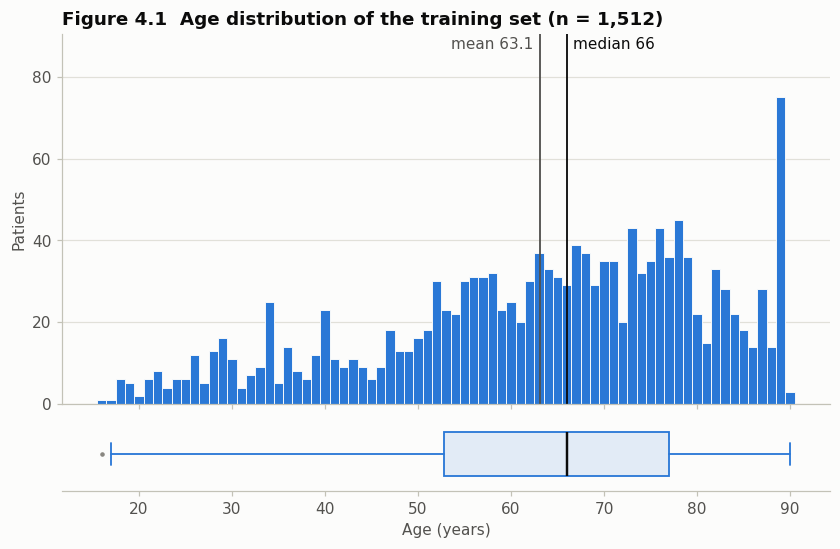

In [8]:
edges = np.arange(age_train.min() - 0.5, age_train.max() + 1.5, 1.0)   # one bar per whole year
mean, median = age_train.mean(), np.median(age_train)

fig, (ax, axb) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True,
                              gridspec_kw={"height_ratios": [5, 1], "hspace": 0.06})
ax.hist(age_train, bins=edges, color=C["real"], edgecolor=C["surface"], linewidth=0.6)
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)   # headroom for the mean/median labels
ax.set_ylabel("Patients")
ax.set_title(f"Figure 4.1  Age distribution of the training set (n = {n:,})")

# Mean and median: thin reference lines with direct labels on opposite sides so they do not collide.
left, right = sorted([(mean, f"mean {mean:.1f}", C["ink2"]), (median, f"median {median:.0f}", C["ink"])])
for (value, label, color), ha, dx in [(left, "right", -4), (right, "left", 4)]:
    ax.axvline(value, color=color, linewidth=1.2)
    ax.annotate(label, (value, 1.0), xycoords=ax.get_xaxis_transform(), xytext=(dx, -2),
                textcoords="offset points", ha=ha, va="top", color=color)

axb.boxplot(age_train, orientation="horizontal", widths=0.6, patch_artist=True,
            boxprops=dict(facecolor=to_rgba(C["real"], 0.12), edgecolor=C["real"], linewidth=1.2),
            medianprops=dict(color=C["ink"], linewidth=1.6),
            whiskerprops=dict(color=C["real"], linewidth=1.2),
            capprops=dict(color=C["real"], linewidth=1.2),
            flierprops=dict(marker="o", markersize=4, markerfacecolor=C["muted"],
                            markeredgecolor=C["surface"], linestyle="none"))
axb.set_yticks([])
axb.grid(False)
axb.spines["left"].set_visible(False)
axb.set_xlabel("Age (years)")

fig.savefig(FIG_DIR / "fig4_1_train_age_histogram.png")
plt.show()

**Figure 4.1.** *Top:* number of training patients at each age, one bar per year. The vertical lines mark the
mean and the median. *Bottom:* box plot of the same ages. The box spans the middle 50% of patients (25th to 75th
percentile), the centre line is the median, the whiskers reach the furthest ages within 1.5 box-widths of the box,
and dots are ages beyond that.

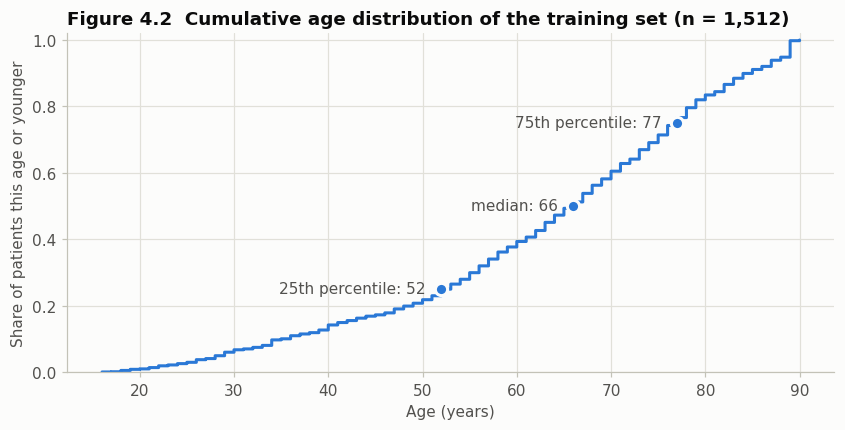

In [9]:
x = np.sort(age_train)
y = np.arange(1, n + 1) / n

fig, ax = plt.subplots(figsize=(9, 4))
ax.step(x, y, where="post", color=C["real"])
for p, name in [(0.25, "25th percentile"), (0.50, "median"), (0.75, "75th percentile")]:
    v = np.quantile(age_train, p, method="inverted_cdf")
    ax.plot(v, p, "o", markersize=8, color=C["real"], markeredgecolor=C["surface"], markeredgewidth=2)
    ax.annotate(f"{name}: {v:.0f}", (v, p), xytext=(-10, 0), textcoords="offset points",
                ha="right", va="center", color=C["ink2"])
ax.set_ylim(0, 1.02)
ax.grid(True, axis="both")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Share of patients this age or younger")
ax.set_title(f"Figure 4.2  Cumulative age distribution of the training set (n = {n:,})")

fig.savefig(FIG_DIR / "fig4_2_train_age_ecdf.png")
plt.show()

**Figure 4.2.** Empirical cumulative distribution (ECDF): for each age on the x-axis, the share of training
patients that age or younger. Dots mark the 25th percentile, median and 75th percentile. Unlike a histogram, the
ECDF needs no bin width, and it is the basis of the two distance metrics used later to compare generated and real
ages (Kolmogorov–Smirnov and Wasserstein).

### 4.4 The tails
The youngest and oldest ages are the hardest part for a GAN, so we look at them directly.

In [10]:
counts = pd.Series(age_train).value_counts().sort_index()
table = pd.DataFrame({"patients": counts, "% of training set": (100 * counts / n).round(2)})
table.index.name = "age"

print("Youngest ages")
display(table.head(8))
print("Oldest ages")
display(table.tail(8))

spike = int(counts.idxmax())   # most common age
neighbours = counts.reindex(range(spike - 5, spike), fill_value=0)
print(f"Most common age: {spike}, with {counts[spike]} patients ({100 * counts[spike] / n:.1f}% of training set), "
      f"{counts[spike] / neighbours.mean():.1f}x the average count at ages {spike - 5}-{spike - 1}.")
print(f"Patients older than {spike}: {(age_train > spike).sum()} ({100 * (age_train > spike).mean():.1f}%).")

Youngest ages


,patients,% of training set
age,,
16,1,0.07
17,1,0.07
18,6,0.40
19,5,0.33
20,2,0.13
21,6,0.40
22,8,0.53
23,4,0.26


Oldest ages


,patients,% of training set
age,,
83,28,1.85
84,22,1.46
85,18,1.19
86,14,0.93
87,28,1.85
88,14,0.93
89,75,4.96
90,3,0.20


Most common age: 89, with 75 patients (5.0% of training set), 3.9x the average count at ages 84-88.
Patients older than 89: 3 (0.2%).


### 4.5 Findings and what they mean for the model

| What the training set shows | What it means for the GAN |
|---|---|
| **Clean data.** No missing, negative, zero or implausible ages, and every whole age from 16 to 90 occurs. Two patients are 16–17. | No cleaning rule is needed, so validation and test data are used exactly as stored. The teenagers are valid ages and stay. |
| **Whole numbers only** (75 distinct ages). | A GAN outputs continuous numbers. Train on ages plus small uniform noise in [−0.5, 0.5) ("dequantization"), and round generated ages back to whole years. |
| **Skewed to the left, not bell-shaped.** Mean 63.1 is below the median 66 (skewness −0.59). Counts rise slowly from 16 to about 50, stay broad from 52 to 80, then fall. | A normal distribution will fit poorly, which makes it a useful weak baseline. The generator has to learn an asymmetric shape with a long lower tail. |
| **Spike at 89.** 75 patients (5.0%): the most common age, and 3.9× the average count at ages 84–88. Only 3 patients (0.2%) are 90. | eICU reports ages above 89 only as "> 89", and in this file they appear to be stored as 89, so 89 most likely means "89 or older". A point mass next to the upper edge is the hardest feature for a GAN, so it gets its own check: the share of generated patients at 89. |
| **Noisy single-year counts.** About 20 patients per year on average, with a few isolated bumps (ages 34 and 40). | Single bars are unreliable at this sample size. The fit is judged with whole-distribution metrics (Wasserstein distance, KS statistic), not bar by bar. |
| **Split note.** Fewer than 10 records in the whole file are 90 or older, so that stratification band was merged into 70–89. | Works as designed; no effect on the model. |

## 5. Preprocessing (parameters from the training set only)

Three steps turn whole-year ages into what the GAN trains on, and turn generator output back into ages:

1. **Dequantization (training data only).** Each training age gets fresh uniform noise in [−0.5, 0.5) every time
   it is used, so age 66 becomes any value in [65.5, 66.5). The discriminator then sees a continuous distribution
   instead of 75 isolated spikes, and the noise also works as mild data augmentation.
2. **Scaling.** Subtract the training mean and divide by the training standard deviation. The generator ends in a
   linear layer (no tanh), so it can reach both ends of the age range, including the spike at 89.
3. **Back to ages.** Generator output is unscaled, rounded to whole years, and clipped to the training range
   (option A: the data are kept exactly as stored). Each year *k* covers [*k* − 0.5, *k* + 0.5), the same interval
   used in step 1, so rounding a dequantized age always gives back the original age.

Validation and test ages are never transformed: every comparison is made in whole years.

In [11]:
PREP = {
    "mean": float(age_train.mean()),   # scaling centre
    "std": float(age_train.std()),     # scaling width
    "lo": int(age_train.min()),        # clipping range for generated ages
    "hi": int(age_train.max()),
}


def dequantize(ages, rng):
    """Spread each whole-year age uniformly over [age - 0.5, age + 0.5)."""
    return ages + rng.uniform(-0.5, 0.5, size=np.shape(ages))


def scale(ages):
    """Ages in years -> model units (training mean 0, standard deviation 1)."""
    return (np.asarray(ages, dtype=np.float64) - PREP["mean"]) / PREP["std"]


def unscale(x):
    """Model units -> continuous ages in years."""
    return np.asarray(x, dtype=np.float64) * PREP["std"] + PREP["mean"]


def to_whole_years(ages):
    """Continuous ages -> whole years (year k covers [k - 0.5, k + 0.5)), clipped to the training range."""
    return np.clip(np.floor(np.asarray(ages) + 0.5), PREP["lo"], PREP["hi"]).astype(np.int64)


pd.Series(PREP, name="value (training set)").to_frame()

,value (training set)
mean,63.080688
std,17.700031
lo,16.000000
hi,90.000000


In [12]:
# Checks: the transforms are exact inverses, and dequantization never changes the rounded age.
check_rng = np.random.default_rng(SEED)
assert np.array_equal(to_whole_years(unscale(scale(age_train))), age_train)
for _ in range(20):
    assert np.array_equal(to_whole_years(dequantize(age_train, check_rng)), age_train)

z = scale(age_train)
print(f"Training ages in model units: {z.min():.2f} to {z.max():.2f} (mean {z.mean():.2f}, std {z.std():.2f})")
print(f"Age 89 occupies model units [{scale(88.5):.3f}, {scale(89.5):.3f})")
print("All preprocessing checks passed.")

Training ages in model units: -2.66 to 1.52 (mean 0.00, std 1.00)
Age 89 occupies model units [1.436, 1.493)
All preprocessing checks passed.


## 6. Evaluation metrics, noise floor and baselines
The validation set is opened here for the first time. It is used only to score models and to choose the one
setting the baselines have (the KDE bandwidth). It is never used for training.

In [13]:
age_val = get_split("val")
n_val = len(age_val)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
print(f"Validation set: {n_val} patients")

Validation set: 504 patients


### 6.1 Metrics
Every model (baselines now, the GAN later) is scored the same way: draw 100,000 ages from it, convert them to whole
years, and compare them with the validation ages. A sample this large keeps the model's own sampling noise far below
the noise floor in 6.2 (with 10,000 samples it was still about 0.2 years of Wasserstein distance).

| Metric | What it measures | How to read it |
|---|---|---|
| **Wasserstein distance** (overall shape) | area between the two cumulative distributions | average number of years patients would have to be shifted to turn one distribution into the other |
| KS statistic | largest vertical gap between the two cumulative distributions | biggest difference in "share of patients this age or younger" |
| **JS divergence** (single ages) | difference between the two one-year histograms, age by age | 0 = identical, 1 = no overlap; sensitive to spikes such as 89 |
| mean, std, 5th / 95th percentile, % under 30, % at 89, % at 90 | simple summaries | checks for mode collapse (too narrow), missing tails, and the 89 spike |

Models are chosen with Wasserstein and JS together (Section 9). Table 6.1 and the simulation in Section 7 show why
this pair.

In [14]:
from scipy.spatial.distance import jensenshannon

N_GEN = 100_000  # ages drawn from every model for evaluation
N_BOOT = 1000    # repeats for the noise floor
DISTANCES = ["Wasserstein (years)", "KS statistic", "JS divergence"]


def describe(ages):
    """Simple summaries of a set of whole-year ages."""
    return {
        "mean": ages.mean(),
        "std": ages.std(ddof=1),
        "5th pct": np.percentile(ages, 5, method="inverted_cdf"),
        "median": np.percentile(ages, 50, method="inverted_cdf"),
        "95th pct": np.percentile(ages, 95, method="inverted_cdf"),
        "% under 30": 100 * np.mean(ages < 30),
        "% at 89": 100 * np.mean(ages == 89),
        "% at 90": 100 * np.mean(ages == 90),
    }


def compare(model_ages, ref_ages):
    """Distances between model ages and reference (real) ages, plus summaries of the model ages."""
    lo = min(model_ages.min(), ref_ages.min())
    hi = max(model_ages.max(), ref_ages.max())
    edges = np.arange(lo - 0.5, hi + 1.5)
    p = np.histogram(model_ages, edges)[0] / len(model_ages)
    q = np.histogram(ref_ages, edges)[0] / len(ref_ages)
    return {
        "Wasserstein (years)": stats.wasserstein_distance(model_ages, ref_ages),
        "KS statistic": stats.ks_2samp(model_ages, ref_ages).statistic,
        "JS divergence": jensenshannon(p, q, base=2) ** 2,
        **describe(model_ages),
    }


def fmt_table(df):
    """Format a results table for display: 3 decimals for KS/JS, 2 for the rest, '—' for empty cells."""
    out = df.astype(object).copy()
    for col in df:
        digits = 3 if col in ("KS statistic", "JS divergence") else 2
        out[col] = df[col].map(lambda v: "—" if pd.isna(v) else f"{v:.{digits}f}")
    return out

### 6.2 Noise floor: the best score any model can expect
Even a perfect model would not score zero, because the validation set has only 504 patients and its histogram is
itself noisy. We estimate this floor from the training set alone: draw 504 ages from the training set (with
replacement) 1,000 times, and measure each draw's distance to the full training set. The floor is the **mean** of
these 1,000 distances. A model whose validation score falls within the range of these distances (for Wasserstein,
95% of them lie between 0.32 and 0.78 years, printed below) cannot be told apart from a perfect model with 504
validation patients: any flaw it still has is smaller than the noise of the validation set.

The draws are stratified by the same age bands as the split in Section 3, because the validation set was drawn
that way too. Without stratification the floor came out almost twice as high (0.9 instead of 0.5 years), which
would make every model look better than it is.

In [15]:
floor_rng = np.random.default_rng(SEED + 1)
train_bands, _ = make_strata(age_train, STRATA_EDGES)   # same bands as the split
band_ids, band_counts = np.unique(train_bands, return_counts=True)
band_sizes = np.round(band_counts / n * n_val).astype(int)   # validation-sized draw, same band mix


def stratified_draw(rng):
    return np.concatenate([rng.choice(age_train[train_bands == b], size=m)
                           for b, m in zip(band_ids, band_sizes)])


floor_runs = pd.DataFrame([compare(age_train, stratified_draw(floor_rng))
                           for _ in range(N_BOOT)])[DISTANCES]
floor = floor_runs.mean()
floor_range = floor_runs.quantile([0.025, 0.975])
for d in DISTANCES:
    print(f"{d:<20} floor {floor[d]:.3f}   (95% of draws between {floor_range.loc[0.025, d]:.3f} "
          f"and {floor_range.loc[0.975, d]:.3f})")

Wasserstein (years)  floor 0.501   (95% of draws between 0.317 and 0.782)
KS statistic         floor 0.025   (95% of draws between 0.014 and 0.041)
JS divergence        floor 0.029   (95% of draws between 0.020 and 0.038)


### 6.3 Baselines
Three simple models, all fitted on the training set. They work directly in years, so unlike the GAN they need no
unscaling. Their samples are rounded to whole years and clipped to 16–90 exactly like the GAN's ages; resampled
training ages are already whole years in that range. They show what a GAN has to beat.

- **Normal fit:** a bell curve with the training mean and standard deviation. A deliberately weak baseline: the
  data are skewed and have the spike at 89.
- **KDE (kernel density estimate):** each sample is a random training age plus Gaussian noise of width *h*
  (the bandwidth), i.e. a smoothed version of the training histogram:
  $\;\hat f_h(x) = \frac{1}{n}\sum_{i=1}^{n} \frac{1}{h}\,\varphi\!\left(\frac{x - x_i}{h}\right)$,
  where $x_1, \dots, x_n$ are the $n = 1{,}512$ training ages and $\varphi$ is the standard normal density.
  Sample $k$ is $x_{i_k} + h\,\varepsilon_k$, where the training-age index $i_k$ is drawn at random and
  $\varepsilon_k \sim N(0, 1)$.
  *h* is chosen on the validation set by log-likelihood, the standard criterion for KDE bandwidths:
  - **Likelihood of one validation age $a$:** the probability that a rounded, clipped sample equals $a$, i.e.
    $\hat f_h$ integrated from $a - 0.5$ to $a + 0.5$:
    $\;\hat P_h(a) = \frac{1}{n}\sum_{i=1}^{n}\left[\Phi\!\left(\frac{a + 0.5 - x_i}{h}\right) - \Phi\!\left(\frac{a - 0.5 - x_i}{h}\right)\right]$,
    where $\Phi$ is the standard normal cumulative distribution function. Clipping adds the outer tails to the
    edge ages: for $a = 16$ the lower limit $a - 0.5$ becomes $-\infty$, and for $a = 90$ the upper limit
    $a + 0.5$ becomes $+\infty$.
  - **Likelihood of the validation set:** the product over its $m = 504$ ages $a_1, \dots, a_m$:
    $\;L(h) = \prod_{j=1}^{m} \hat P_h(a_j)$.
  - **Mean log-likelihood per patient** (natural log), plotted in Figure 6.1 (left):
    $\;\bar\ell(h) = \frac{1}{m}\log L(h) = \frac{1}{m}\sum_{j=1}^{m}\log \hat P_h(a_j)$.
    Dividing by $m$ makes the number easier to read and does not change which $h$ wins. The chosen $h$ is the one
    with the highest $\bar\ell(h)$ among 25 values from 0.25 to 12 years, evenly spaced on a log scale. The one
    validation patient aged 15 is counted at 16.
- **KDE with Silverman's rule:** the same model with the textbook default bandwidth
  $\;h = 1.06\, s\, n^{-1/5}$, where $s = 17.71$ years is the standard deviation of the training ages and
  $n = 1{,}512$ is their number. This gives $h = 4.34$ years and needs no validation data. It shows what ordinary
  smoothing does to the spike at 89.
- **Resampled training ages:** draws training ages with replacement. This model has memorised the training set,
  so it is the natural "copy the data" reference. A GAN should get close to it without copying.

**How each baseline is compared with the validation set.** Like every model (Section 6.1), each baseline is scored
from a sample of its ages, not from its formula, because the GAN can only be sampled:
1. **Draw 100,000 ages.** One set of random numbers is drawn once and shared by all baselines: for
   $k = 1, \dots, 100{,}000$, a random training-age index $i_k$ and a standard normal number $\varepsilon_k$.
   Sample $k$ is then $\bar x + s\,\varepsilon_k$ for the normal fit (with $\bar x = 63.08$ years, the training
   mean), $x_{i_k} + h\,\varepsilon_k$ for the KDEs, and $x_{i_k}$ for the resampled training ages. Because the
   random numbers are shared, the baselines differ only by their model, not by luck.
2. **Round and clip** to whole years 16–90 (resampled ages are already whole years in that range).
3. **Compare with the 504 validation ages** using the metrics of Section 6.1. Wasserstein distance and KS
   compare the two sets of ages directly, through their cumulative distributions. JS divergence compares their
   one-year histograms: the share of each set at each age. Figure 6.2 plots these shares, validation as blue bars
   and the model as an orange line.

Only the choice of the KDE bandwidth uses a formula directly ($\hat P_h$ above) instead of samples.

In [16]:
base_rng = np.random.default_rng(SEED + 2)
idx = base_rng.integers(n, size=N_GEN)   # indexes of same random draws reused for every bandwidth (fair comparison)
eps = base_rng.standard_normal(N_GEN)   # eps holds 100,000 draws from the standard normal N(0, 1)

support = np.arange(PREP["lo"], PREP["hi"] + 1)
lower = np.where(support == PREP["lo"], -np.inf, support - 0.5)   # clipping puts the outer tails
upper = np.where(support == PREP["hi"], np.inf, support + 0.5)    # into the first and last year


def kde_val_loglik(h, ages=age_val):
    """Mean log-likelihood of (validation) ages under the KDE, after rounding and clipping."""
    cdf = lambda b: stats.norm.cdf((b[None, :] - age_train[:, None]) / h)
    pmf = (cdf(upper) - cdf(lower)).mean(axis=0)   # probability of each whole year
    return np.log(pmf[np.clip(ages, PREP["lo"], PREP["hi"]) - PREP["lo"]]).mean()


H_GRID = np.geomspace(0.25, 12, 25)
kde_scan = pd.DataFrame([{
    "bandwidth": h,
    "val log-likelihood": kde_val_loglik(h),
    "val Wasserstein": stats.wasserstein_distance(to_whole_years(age_train[idx] + h * eps), age_val),
} for h in H_GRID])
h_best = float(kde_scan.loc[kde_scan["val log-likelihood"].idxmax(), "bandwidth"])
h_silverman = 1.06 * age_train.std(ddof=1) * n ** (-1 / 5)
print(f"Chosen KDE bandwidth: {h_best:.2f} years (Silverman's rule of thumb would give {h_silverman:.2f})")

# Side check: what drives the choice? Repeat it without the validation ages next to the spike (87-90).
h_no_spike = H_GRID[np.argmax([kde_val_loglik(h, age_val[age_val < 87]) for h in H_GRID])]
print(f"Leaving out validation ages 87-90, the best bandwidth would be {h_no_spike:.2f} years")

Chosen KDE bandwidth: 0.48 years (Silverman's rule of thumb would give 4.34)
Leaving out validation ages 87-90, the best bandwidth would be 2.04 years


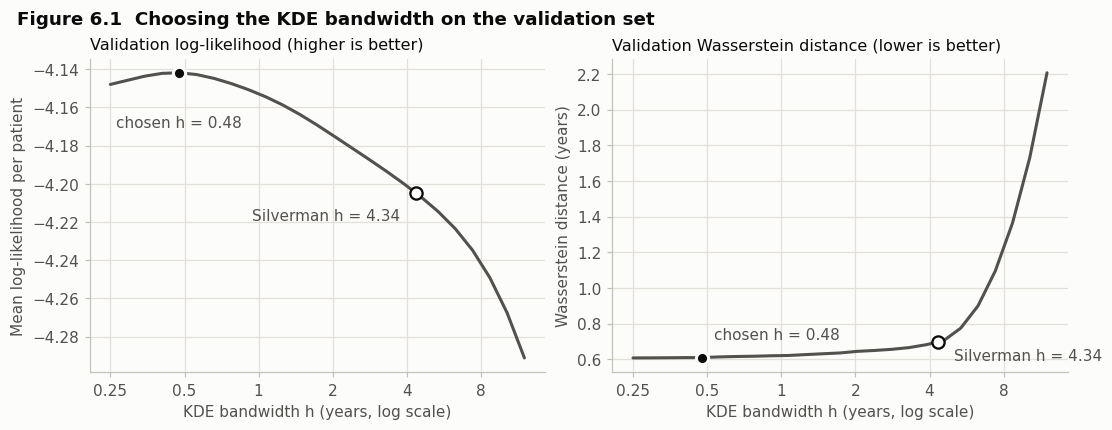

In [17]:
best = kde_scan.loc[kde_scan["bandwidth"] == h_best].iloc[0]
silverman_ll = kde_val_loglik(h_silverman)
silverman_w1 = stats.wasserstein_distance(to_whole_years(age_train[idx] + h_silverman * eps), age_val)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
# (column, y label, panel title, Silverman value, label placement for the chosen and Silverman points)
panels = [("val log-likelihood", "Mean log-likelihood per patient", "Validation log-likelihood (higher is better)",
           silverman_ll, dict(xytext=(0, -28), ha="center", va="top"),
           dict(xytext=(-10, -10), ha="right", va="top")),
          ("val Wasserstein", "Wasserstein distance (years)", "Validation Wasserstein distance (lower is better)",
           silverman_w1, dict(xytext=(8, 10), ha="left", va="bottom"),
           dict(xytext=(10, -4), ha="left", va="top"))]
for ax, (col, ylabel, title, s_val, lab_best, lab_s) in zip(axes, panels):
    ax.plot(kde_scan["bandwidth"], kde_scan[col], color=C["ink2"])
    ax.plot(h_best, best[col], "o", markersize=8, color=C["ink"], markeredgecolor=C["surface"], markeredgewidth=2)
    ax.annotate(f"chosen h = {h_best:.2f}", (h_best, best[col]), textcoords="offset points", color=C["ink2"],
                **lab_best)
    ax.plot(h_silverman, s_val, "o", markersize=8, markerfacecolor=C["surface"], markeredgecolor=C["ink"],
            markeredgewidth=1.5)
    ax.annotate(f"Silverman h = {h_silverman:.2f}", (h_silverman, s_val), textcoords="offset points",
                color=C["ink2"], **lab_s)
    ax.set_xscale("log")
    ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
    ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
    ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.grid(True, axis="both")
    ax.set_xlabel("KDE bandwidth h (years, log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10.5, fontweight="normal")
fig.suptitle("Figure 6.1  Choosing the KDE bandwidth on the validation set",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig6_1_kde_bandwidth.png")
plt.show()

**Figure 6.1.** Score of the KDE baseline on the validation set for 25 bandwidths *h* (log scale). *Left:* mean
log-likelihood of the validation ages (higher is better), which picks the bandwidth. *Right:* Wasserstein distance
to the validation ages for the same bandwidths (lower is better), shown for comparison. The filled dot marks the
chosen bandwidth, the open dot the textbook default (Silverman's rule).

### 6.4 Baseline results on the validation set

In [18]:
baselines = {
    "Normal fit": to_whole_years(age_train.mean() + age_train.std(ddof=1) * eps),
    f"KDE (h = {h_best:.2f}, chosen on validation)": to_whole_years(age_train[idx] + h_best * eps),
    f"KDE (h = {h_silverman:.2f}, Silverman's rule)": to_whole_years(age_train[idx] + h_silverman * eps),
    "Resampled training ages": age_train[idx],
}

rows = {"Validation set (target)": {**{d: np.nan for d in DISTANCES}, **describe(age_val)},
        "Noise floor (perfect model)": floor.to_dict()}
rows.update({name: compare(ages, age_val) for name, ages in baselines.items()})
results = pd.DataFrame(rows).T[DISTANCES + list(describe(age_val))]
results.to_csv(RESULTS_DIR / "baselines_validation.csv")
fmt_table(results)

,Wasserstein (years),KS statistic,JS divergence,mean,std,5th pct,median,95th pct,% under 30,% at 89,% at 90
Validation set (target),—,—,—,63.59,17.87,28.00,66.00,89.00,6.15,5.36,0.00
Noise floor (perfect model),0.50,0.025,0.029,—,—,—,—,—,—,—,—
Normal fit,2.62,0.083,0.097,62.67,16.65,34.00,63.00,90.00,2.85,0.78,6.80
"KDE (h = 0.48, chosen on validation)",0.61,0.029,0.039,63.17,17.72,28.00,66.00,88.00,6.04,3.72,0.90
"KDE (h = 4.34, Silverman's rule)",0.69,0.040,0.065,63.10,18.06,28.00,66.00,89.00,5.92,1.10,4.04
Resampled training ages,0.61,0.030,0.041,63.17,17.71,29.00,66.00,89.00,6.06,5.03,0.19


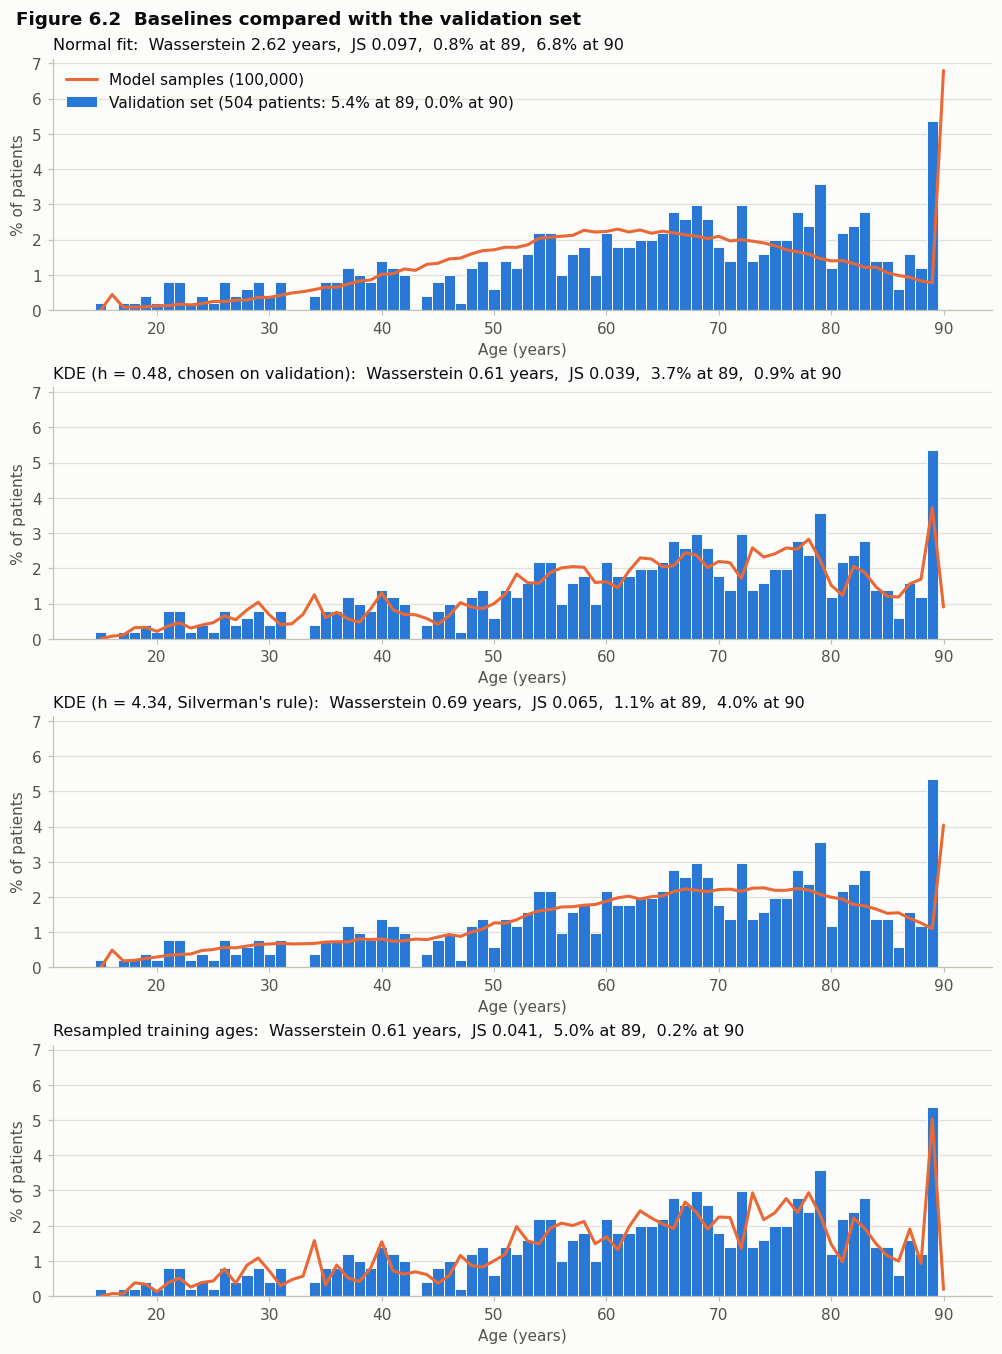

In [19]:
k = np.arange(min(age_val.min(), PREP["lo"]), max(age_val.max(), PREP["hi"]) + 1)
share = lambda ages: 100 * np.array([np.mean(ages == a) for a in k])
val_share = share(age_val)

fig, axes = plt.subplots(len(baselines), 1, figsize=(9, 2.9 * len(baselines) + 0.6),
                         sharex=True, sharey=True, layout="constrained")
val_spike = results.loc["Validation set (target)"]
for ax, (name, ages) in zip(axes, baselines.items()):
    r = results.loc[name]
    ax.bar(k, val_share, width=1.0, color=C["real"], edgecolor=C["surface"], linewidth=0.6,
           label=f"Validation set ({n_val} patients: {val_spike['% at 89']:.1f}% at 89, "
                 f"{val_spike['% at 90']:.1f}% at 90)")
    ax.plot(k, share(ages), color=C["generated"], label=f"Model samples ({N_GEN:,})")
    ax.set_title(f"{name}:  Wasserstein {r['Wasserstein (years)']:.2f} years,  JS {r['JS divergence']:.3f},  "
                 f"{r['% at 89']:.1f}% at 89,  {r['% at 90']:.1f}% at 90", fontsize=10.5, fontweight="normal")
    ax.set_ylabel("% of patients")
    ax.set_xlabel("Age (years)")
    ax.tick_params(axis="x", labelbottom=True)   # sharex hides the age numbers on all but the bottom panel
axes[0].legend(loc="upper left")
fig.suptitle("Figure 6.2  Baselines compared with the validation set", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig6_2_baselines_vs_validation.png")
plt.show()

**Figure 6.2.** Each panel compares one baseline with the validation set. Blue bars: share of validation patients
at each age. Orange line: share of the baseline's 100,000 generated ages at each age. The panel title gives the
Wasserstein distance and JS divergence (both lower is better) and the model's shares at ages 89 and 90; the legend
gives the validation shares. With 504 validation patients each bar holds only about 7 patients, so the bars are
noisy; the distances summarise the fit over all ages. The leftmost bar is one validation patient aged 15, younger
than anyone in the training set; no model clipped to 16–90 can produce this age, and its effect on the scores is
negligible. Compare the Silverman KDE with the resampled training ages: almost the same Wasserstein distance, but a
much larger JS divergence, and its spike at 89 is visibly smeared into 88 and 90. Table 6.1 shows where that
difference comes from.

**Table 6.1. JS divergence picks up the spike; Wasserstein distance barely does.** Both distances add up over ages,
so they can be split into the part from the spike region and the rest. JS divergence is a sum of one term per age.
Wasserstein distance is a sum of one term per boundary between neighbouring ages: the share of patients that has to
be moved across that boundary. The first two columns show how well each baseline keeps the spike (validation set:
5.4% at 89, none at 90).

In [20]:
SPIKE_AGES = (88, 89, 90)


def split_by_age(model_ages, ref_ages, ages=SPIKE_AGES):
    """Split JS divergence and Wasserstein distance into the part from the given ages and the rest."""
    grid = np.arange(min(model_ages.min(), ref_ages.min()), max(model_ages.max(), ref_ages.max()) + 1)
    p = np.bincount(model_ages - grid[0], minlength=len(grid)) / len(model_ages)
    q = np.bincount(ref_ages - grid[0], minlength=len(grid)) / len(ref_ages)
    mid = (p + q) / 2
    with np.errstate(divide="ignore", invalid="ignore"):
        js_term = 0.5 * (np.where(p > 0, p * np.log2(p / mid), 0) + np.where(q > 0, q * np.log2(q / mid), 0))
    w_term = np.abs(np.cumsum(p) - np.cumsum(q))   # share moved across the boundary between age a and a + 1
    in_js = np.isin(grid, ages)
    in_w = (grid >= min(ages) - 1) & (grid < max(ages))   # the boundaries 87|88, 88|89 and 89|90
    return {"JS total": js_term.sum(), "JS spike": js_term[in_js].sum(), "JS other": js_term[~in_js].sum(),
            "W total": w_term.sum(), "W spike": w_term[in_w].sum()}


parts = pd.DataFrame({name: split_by_age(ages, age_val) for name, ages in baselines.items()}).T
assert np.allclose(parts["JS total"], results.loc[list(baselines), "JS divergence"])          # same as compare()
assert np.allclose(parts["W total"], results.loc[list(baselines), "Wasserstein (years)"])

pct = lambda part, total: f"{part:.3f} ({100 * part / total:.0f}%)"
table_6_1 = pd.DataFrame({
    "% at 89": results.loc[list(baselines), "% at 89"].map("{:.1f}".format),
    "% at 90": results.loc[list(baselines), "% at 90"].map("{:.1f}".format),
    "JS divergence": parts["JS total"].map("{:.3f}".format),
    "JS from ages 88–90": [pct(a, b) for a, b in zip(parts["JS spike"], parts["JS total"])],
    "JS from all other ages": parts["JS other"].map("{:.3f}".format),
    "Wasserstein (years)": parts["W total"].map("{:.2f}".format),
    "Wasserstein from ages 87–90": [f"{a:.2f} ({100 * a / b:.0f}%)" for a, b in zip(parts["W spike"], parts["W total"])],
    "Wasserstein from all other ages": (parts["W total"] - parts["W spike"]).map("{:.2f}".format),
})
table_6_1.to_csv(RESULTS_DIR / "table6_1_distance_by_age.csv")
table_6_1

,% at 89,% at 90,JS divergence,JS from ages 88–90,JS from all other ages,Wasserstein (years),Wasserstein from ages 87–90,Wasserstein from all other ages
Normal fit,0.8,6.8,0.097,0.048 (49%),0.049,2.62,0.11 (4%),2.51
"KDE (h = 0.48, chosen on validation)",3.7,0.9,0.039,0.006 (15%),0.033,0.61,0.02 (3%),0.59
"KDE (h = 4.34, Silverman's rule)",1.1,4.0,0.065,0.031 (48%),0.033,0.69,0.04 (6%),0.65
Resampled training ages,5.0,0.2,0.041,0.001 (3%),0.040,0.61,0.01 (1%),0.60


Ages 88–90 are 3 of the 76 ages compared, yet they carry about half of the JS divergence of the two baselines that
lose the spike: 48% for the Silverman KDE (0.031 of 0.065) and 49% for the normal fit. For the resampled training
ages, which keep the spike, they carry 3%. On all other ages the Silverman KDE is slightly *better* than the
resampled training ages (0.033 against 0.040), because smoothing removes noise, so the whole JS gap between these
two models comes from the spike. The same ages add only 0.04 years (6%) to the Silverman KDE's Wasserstein distance.

The overall shape works the other way round. Away from the spike (the two "all other ages" columns), the normal fit
is about 4 times further off than the resampled training ages on Wasserstein distance (2.51 against 0.60 years), but
only slightly on JS divergence (0.049 against 0.040). JS compares the shares age by
age and ignores how far apart the ages are, so a shape that is off by a few years everywhere adds little on top of
the noise in the one-year shares of 504 patients. Wasserstein distance counts how far patients would have to move,
so it sees the wrong shape. Each metric sees what the other misses; Section 7 tests this in a controlled
simulation.

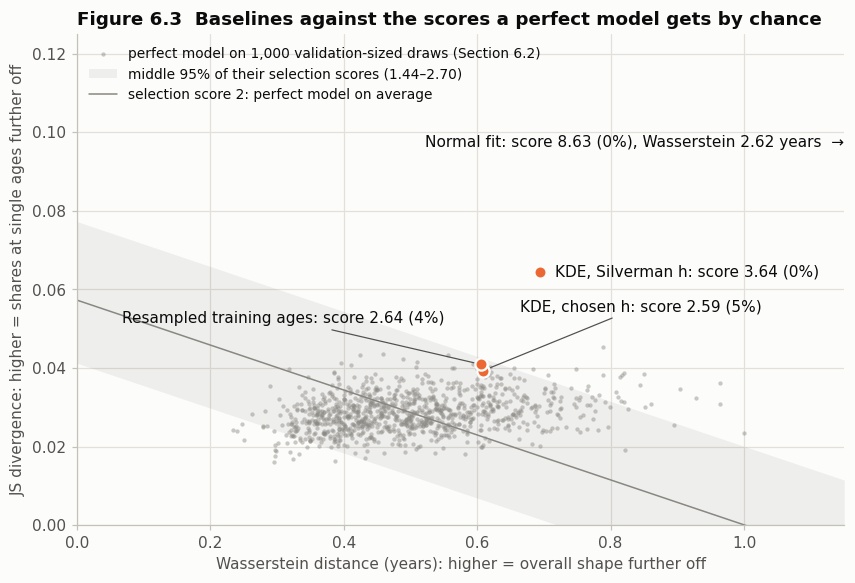

In [21]:
short = dict(zip(baselines, ["Normal fit", "KDE, chosen h", "KDE, Silverman h", "Resampled training ages"]))
fw, fj = floor["Wasserstein (years)"], floor["JS divergence"]
score = lambda w1, js: w1 / fw + js / fj   # the selection score used from Section 9 on
cloud_w, cloud_js = floor_runs["Wasserstein (years)"], floor_runs["JS divergence"]
cloud = score(cloud_w, cloud_js)
lo95, hi95 = cloud.quantile([0.025, 0.975])
X_MAX, Y_MAX = 1.15, 0.125   # headroom at the top for the legend

fig, ax = plt.subplots(figsize=(9, 5.8))
ax.grid(True, axis="both")
w = np.array([0.0, X_MAX])
line = lambda s: fj * (s - w / fw)   # JS on the line of constant score s
band = ax.fill_between(w, line(lo95), line(hi95), color=to_rgba(C["ink2"], 0.08), linewidth=0)
mean_line, = ax.plot(w, line(2.0), color=C["muted"], linewidth=1)
dots = ax.scatter(cloud_w, cloud_js, s=8, color=C["muted"], alpha=0.45, linewidth=0)

# label offsets in points. The chosen KDE and the resampled ages almost overlap, so their labels go into the empty
# space above the cloud, one to each side, with a leader line to the point.
offsets = {"KDE, chosen h": (24, 42), "KDE, Silverman h": (10, 0), "Resampled training ages": (-24, 30)}
for name in baselines:
    w1, js = results.loc[name, ["Wasserstein (years)", "JS divergence"]]
    s = score(w1, js)
    label = f"{short[name]}: score {s:.2f} ({100 * np.mean(cloud > s):.0f}%)"
    if w1 <= X_MAX:
        ax.plot(w1, js, "o", markersize=8, color=C["generated"], markeredgecolor=C["surface"], markeredgewidth=1.5)
        dx, dy = offsets[short[name]]
        leader = dict(arrowstyle="-", color=C["ink2"], linewidth=0.8, shrinkA=2, shrinkB=5) if dy else None
        ax.annotate(label, (w1, js), xytext=(dx, dy), textcoords="offset points", ha="left" if dx > 0 else "right",
                    va="center", color=C["ink"], arrowprops=leader)
    else:   # off the scale: label at the right edge, at its JS height
        ax.annotate(f"{label}, Wasserstein {w1:.2f} years  →", (1.0, js), xycoords=("axes fraction", "data"),
                    ha="right", va="center", color=C["ink"])
ax.set_xlim(0, X_MAX)
ax.set_ylim(0, Y_MAX)
ax.set_xlabel("Wasserstein distance (years): higher = overall shape further off")
ax.set_ylabel("JS divergence: higher = shares at single ages further off")
ax.legend([dots, band, mean_line],
          [f"perfect model on {N_BOOT:,} validation-sized draws (Section 6.2)",
           f"middle 95% of their selection scores ({lo95:.2f}–{hi95:.2f})",
           "selection score 2: perfect model on average"], loc="upper left", fontsize=9)
ax.set_title("Figure 6.3  Baselines against the scores a perfect model gets by chance")
fig.savefig(FIG_DIR / "fig6_3_noise_floor_distribution.png")
plt.show()

**Figure 6.3.** Each baseline's two validation scores, compared with the scores of a perfect model.
- *Axes:* Wasserstein distance (years) and JS divergence to the validation set. Further right means the overall
  shape is further off (shifted, wrong tails, wrong skew). Further up means the shares at single ages are further
  off, for example a lost spike.
- *Gray dots:* the 1,000 draws from Section 6.2, i.e. the scores a perfect model gets on validation-sized samples
  purely by chance.
- *Diagonal lines:* constant selection score, Wasserstein / its floor + JS / its floor (used from Section 9 on). The
  gray line is score 2, a perfect model on average. The shaded band holds the middle 95% of the perfect model's
  scores (1.44–2.70).
- *Orange dots:* the baselines' actual validation scores. The percentage after each score is how often a perfect
  model scored *worse*: a large value means the score is explained by validation noise, 0% means the model is
  clearly off. The normal fit is off the scale to the right (Wasserstein 2.62 years); its label sits at its JS
  divergence, 0.097.

How to read it:
1. **The Silverman KDE is right on shape but wrong on the spike.** Its Wasserstein distance (0.69 years) is within
   the range of the gray dots, but its JS divergence (0.065) is far above them. Only the pair of metrics shows both.
2. **The chosen KDE and the resampled training ages almost coincide, at the top edge of the band** (scores 2.59 and
   2.64; a perfect model scores worse only 5% and 4% of the time). They copy the noise of the 1,512 training ages,
   which the validation set does not share, while the gray dots carry only the validation set's noise. Extra noise
   of this kind raises JS divergence much more than Wasserstein distance (expected: by about a third, 504 / 1,512,
   against about 15%), so it shows mainly as height: the resampled training ages are 43% above the JS floor but only
   21% above the Wasserstein floor. A score of about 2.6 is therefore what copying the training set achieves; a
   model that smooths away some of that noise can do better.
3. **The spread of the dots is the uncertainty of one model's score on its own.** Two models scored on the same
   validation set can be compared more precisely, because much of the luck of the draw affects both alike.

### 6.5 Findings and what they mean for the GAN

- **The target.** A perfect model would score about **0.50 years** of Wasserstein distance on this validation set
  (95% range 0.32–0.78, Section 6.2), with KS 0.025 and JS 0.029. The resampled training ages score 0.61 years,
  inside that range. A GAN at about 0.6 years is as good as this data can show.
- **The normal fit is far off** (2.62 years). It misses the skew and the young tail (2.9% under 30 instead of
  6.2%), and clipping its upper tail piles 6.8% of patients onto age 90, where the validation set has none.
- **Wasserstein distance alone does not see the spike.** Silverman's KDE scores 0.69 years, barely worse than the
  resampled training ages (0.61), yet it shrinks the share at 89 from 5.4% to 1.1% and moves 4.0% of patients to
  90. JS divergence reveals the problem (0.065 against 0.041), and Table 6.1 shows that the whole difference comes
  from ages 88–90.
- **The validation set rewards a sharp spike.** Log-likelihood picks almost no smoothing (h = 0.48 years); without
  validation ages 87–90 it would pick about 2 years. Even that small amount of smoothing moves 0.9% of patients from
  89 to 90.
- **The risk of option A is real.** Every model that smooths the data spills part of the spike into age 90 through
  the clipping step, so the GAN's shares at 89 and 90 must be checked explicitly.

**Implication for model selection:** Wasserstein distance alone is not enough to choose between GAN settings; it
needs a spike-sensitive metric next to it, such as KS, JS divergence or the share at 89. This rests on one example,
so Section 7 tests the candidates in a controlled simulation.

## 7. Choosing the selection metric: a simulation

Section 6.4 showed with one baseline that Wasserstein distance barely notices a smeared spike while JS divergence
does. The metric chosen here will pick GAN checkpoints and settings (Section 9), so this section tests the
candidates in a controlled setting: a known true distribution, damaged in known ways, scored on many simulated
validation sets of the real size. It uses the training set only; the validation set is not touched.

1. **Truth.** A smooth bulk (a KDE with h = 2 years of the training ages below 89, on ages 16–88, reflected at both
   ends so no mass leaks out) plus the training shares at 89 (5.0%) and 90 (0.2%). The bulk is smooth so that the truth has no sampling noise of its own: every
   error a metric sees is one we put in.
2. **Damaged models** (Figure 7.1).
   *Spike:* 25%, 50% or 75% of the mass at 89 moved, half to 88 and half to 90, i.e. a spike the generator has
   blurred. *Shift:* every age below 89 moved up by 1 or 2 years, spike unchanged. *Wiggles:* the bulk multiplied by
   1 ± 15% or 1 ± 30% with a 6-year period, i.e. local bumps and dips away from the spike. *Young tail:* patients
   under 30 thinned by 30%. The perfect model is the truth itself.
3. **1,000 simulated validation sets** of 504 ages each, drawn from the truth and stratified by the split's age
   bands (in the truth's own proportions, so a perfect model is not penalised for a band-mix mismatch). For every
   set, each model draws a **fresh** sample of 100,000 ages, as each new checkpoint does. With one fixed sample per
   model, that sample's own luck would be shared by all 1,000 comparisons and, for the smallest damages, outweigh
   the damage itself.
4. **Scores.** Wasserstein distance, KS statistic, JS divergence and the difference in the share at 89, each divided
   by its floor (the perfect model's mean score), plus the three pairs that add Wasserstein to one of the others.
5. **Miss rate.** For each damaged model and metric: the share of validation sets on which the damaged model scores
   no worse than the perfect model on the *same* set. 0% means the damage is always caught; about 50% means the
   metric cannot tell the two apart. Scoring both on the same set mirrors model selection, where all candidates
   face the same validation set.

In [22]:
sim_rng = np.random.default_rng(SEED + 3)
grid = np.arange(PREP["lo"], PREP["hi"] + 1)
in_bulk = grid < 89
share_89, share_90 = np.mean(age_train == 89), np.mean(age_train == 90)

# Truth: smooth bulk (KDE with h = 2 years of the training ages below 89) plus the training shares at 89 and 90.
# The KDE is reflected at the edges of 16-88 (15.5 and 88.5), so no mass leaks past them; without this the bars
# next to the edges, e.g. age 88 right before the spike, come out too low.
bulk_ages = age_train[age_train < 89]
bulk_ages = np.concatenate([bulk_ages, 2 * (PREP["lo"] - 0.5) - bulk_ages, 2 * 88.5 - bulk_ages])
bulk_cdf = lambda b: stats.norm.cdf((b[None, :] - bulk_ages[:, None]) / 2.0)
bulk = np.where(in_bulk, (bulk_cdf(grid + 0.5) - bulk_cdf(grid - 0.5)).mean(axis=0), 0.0)
truth = (1 - share_89 - share_90) * bulk / bulk.sum() + share_89 * (grid == 89) + share_90 * (grid == 90)
bulk_part = np.where(in_bulk, truth, 0.0)


def smear_spike(frac):
    """Move a fraction of the 89 spike, half to 88 and half to 90."""
    q = truth.copy()
    moved = frac * truth[grid == 89]
    q[grid == 89] -= moved
    q[grid == 88] += moved / 2
    q[grid == 90] += moved / 2
    return q


def reshape_bulk(new_bulk):
    """Replace the bulk (ages below 89) by new_bulk, rescaled to the same total; the spike is kept."""
    new_bulk = np.where(in_bulk, new_bulk, 0.0)
    return np.where(in_bulk, new_bulk * bulk_part.sum() / new_bulk.sum(), truth)


wiggle = lambda size: 1 + size * np.sin(2 * np.pi * grid / 6)
damaged = {
    "Spike: 25% smeared": smear_spike(0.25),
    "Spike: 50% smeared": smear_spike(0.50),
    "Spike: 75% smeared": smear_spike(0.75),
    "Bulk shifted +1 year": reshape_bulk(np.roll(bulk_part, 1)),
    "Bulk shifted +2 years": reshape_bulk(np.roll(bulk_part, 2)),
    "Bulk wiggles ±15%": reshape_bulk(bulk_part * wiggle(0.15)),
    "Bulk wiggles ±30%": reshape_bulk(bulk_part * wiggle(0.30)),
    "Under-30s thinned by 30%": reshape_bulk(bulk_part * np.where(grid < 30, 0.7, 1.0)),
}
sim_models = {"Perfect model": truth, **damaged}
assert all(np.isclose(p.sum(), 1) and (p >= 0).all() for p in sim_models.values())
print(f"Truth: {100 * truth[grid == 89][0]:.1f}% at 89, {100 * truth[grid == 90][0]:.1f}% at 90, "
      f"{100 * truth[grid < 30].sum():.1f}% under 30")

Truth: 5.0% at 89, 0.2% at 90, 5.8% under 30


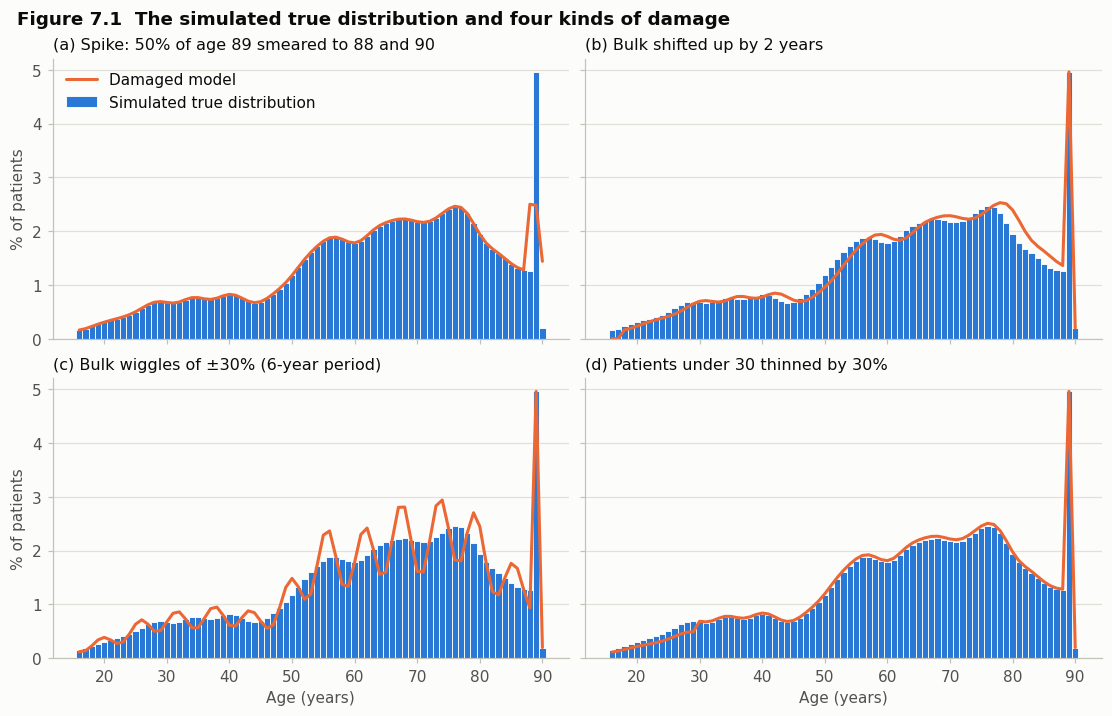

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True, layout="constrained")
shown = [("(a) Spike: 50% of age 89 smeared to 88 and 90", "Spike: 50% smeared"),
         ("(b) Bulk shifted up by 2 years", "Bulk shifted +2 years"),
         ("(c) Bulk wiggles of ±30% (6-year period)", "Bulk wiggles ±30%"),
         ("(d) Patients under 30 thinned by 30%", "Under-30s thinned by 30%")]
for ax, (title, name) in zip(axes.flat, shown):
    ax.bar(grid, 100 * truth, width=1.0, color=C["real"], edgecolor=C["surface"], linewidth=0.6,
           label="Simulated true distribution")
    ax.plot(grid, 100 * sim_models[name], color=C["generated"], label="Damaged model")
    ax.set_title(title, fontsize=10.5, fontweight="normal")
axes[0, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Age (years)")
for ax in axes[:, 0]:
    ax.set_ylabel("% of patients")
fig.suptitle("Figure 7.1  The simulated true distribution and four kinds of damage", x=0.01, ha="left",
             fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig7_1_simulated_damage.png")
plt.show()

**Figure 7.1.** Blue bars: the simulated true distribution, built from the training set (Section 7, step 1). Orange
line: the largest damage of each kind. *(a)* Half of the spike at 89 is smeared into 88 and 90. *(b)* Every age
below 89 moves up 2 years. *(c)* The bulk wiggles by ±30%. *(d)* Patients under 30 are thinned by 30%, and the rest
of the bulk is scaled up to keep the total. The smaller damages in Table 7.1 (25% and 75% smearing, a 1-year shift,
±15% wiggles) have the same form with other sizes.

In [24]:
hist = lambda ages: np.bincount(ages - grid[0], minlength=len(grid)) / len(ages)


def fast_scores(p, q):
    """Wasserstein, KS, JS and |difference in share at 89| from two whole-year histograms on `grid`."""
    gap = np.cumsum(p) - np.cumsum(q)
    mid = (p + q) / 2
    with np.errstate(divide="ignore", invalid="ignore"):
        js = 0.5 * np.sum(np.where(p > 0, p * np.log2(p / mid), 0) + np.where(q > 0, q * np.log2(q / mid), 0))
    return np.abs(gap).sum(), np.abs(gap).max(), js, abs(p[grid == 89][0] - q[grid == 89][0])


age_band = dict(zip(age_train, train_bands))   # every age 16-90 occurs in the training set
grid_band = np.array([age_band[a] for a in grid])
band_mass = np.array([truth[grid_band == b].sum() for b in band_ids]) * n_val   # truth's band mix
sim_band_sizes = np.floor(band_mass).astype(int)
sim_band_sizes[np.argsort(sim_band_sizes - band_mass)[:n_val - sim_band_sizes.sum()]] += 1   # round to n_val total
assert sim_band_sizes.sum() == n_val


def simulated_val_counts(rng):
    """Counts per age of 504 ages drawn from the truth, stratified by the split's age bands."""
    counts = np.zeros(len(grid), dtype=np.int64)
    for b, m in zip(band_ids, sim_band_sizes):
        in_band = grid_band == b
        counts[in_band] += rng.multinomial(m, truth[in_band] / truth[in_band].sum())
    return counts


def model_sample(p, rng):
    """Histogram of a fresh sample of N_GEN ages from a model."""
    return rng.multinomial(N_GEN, p / p.sum()) / N_GEN


# fast_scores() computes the same distances as compare() (checked on one draw), only much faster.
check_model = np.repeat(grid, sim_rng.multinomial(N_GEN, damaged["Spike: 50% smeared"]))
check_val = np.repeat(grid, simulated_val_counts(sim_rng))
check = compare(check_model, check_val)
assert np.allclose(fast_scores(hist(check_model), hist(check_val))[:3], [check[d] for d in DISTANCES])

SIM_METRICS = ["Wasserstein", "KS", "JS", "% at 89"]
raw = {name: np.empty((N_BOOT, len(SIM_METRICS))) for name in sim_models}
for r in range(N_BOOT):
    counts = simulated_val_counts(sim_rng)
    q = counts / counts.sum()
    for name, p in sim_models.items():
        raw[name][r] = fast_scores(model_sample(p, sim_rng), q)   # a fresh model sample for every set
sim_floor = raw["Perfect model"].mean(axis=0)


def scaled_scores(a):
    """Each metric divided by its floor, plus the pairs with Wasserstein."""
    s = pd.DataFrame(a / sim_floor, columns=SIM_METRICS)
    for partner in ["KS", "JS", "% at 89"]:
        s[f"Wasserstein + {partner}"] = s["Wasserstein"] + s[partner]
    return s


perfect_scores = scaled_scores(raw["Perfect model"])
miss = pd.DataFrame({name: 100 * (scaled_scores(raw[name]) <= perfect_scores).mean() for name in damaged}).T
miss.to_csv(RESULTS_DIR / "table7_1_metric_miss_rates.csv")
print(f"Simulated validation sets: {sim_band_sizes.sum()} ages, band sizes {sim_band_sizes.tolist()}")
print(f"Floors in the simulation: Wasserstein {sim_floor[0]:.3f} years, KS {sim_floor[1]:.3f}, "
      f"JS {sim_floor[2]:.3f}, share at 89 {100 * sim_floor[3]:.2f} points")
print(f"(Section 6.2, from the training set: Wasserstein {floor['Wasserstein (years)']:.3f}, "
      f"KS {floor['KS statistic']:.3f}, JS {floor['JS divergence']:.3f})")
miss.round(0).astype(int).astype(str) + "%"

Simulated validation sets: 504 ages, band sizes [29, 77, 187, 211]
Floors in the simulation: Wasserstein 0.510 years, KS 0.025, JS 0.029, share at 89 0.73 points
(Section 6.2, from the training set: Wasserstein 0.501, KS 0.025, JS 0.029)


,Wasserstein,KS,JS,% at 89,Wasserstein + KS,Wasserstein + JS,Wasserstein + % at 89
Spike: 25% smeared,43%,50%,6%,24%,46%,14%,25%
Spike: 50% smeared,27%,43%,0%,7%,34%,1%,8%
Spike: 75% smeared,17%,31%,0%,1%,20%,0%,1%
Bulk shifted +1 year,10%,21%,33%,51%,14%,10%,12%
Bulk shifted +2 years,1%,3%,14%,49%,1%,0%,1%
Bulk wiggles ±15%,38%,39%,15%,48%,36%,20%,45%
Bulk wiggles ±30%,18%,24%,1%,50%,18%,2%,34%
Under-30s thinned by 30%,3%,23%,24%,49%,6%,3%,4%


**Table 7.1. Miss rate of each metric (lower is better).** Share of the 1,000 simulated validation sets on which
the damaged model scores no worse than the perfect model. Rows: the damage (Figure 7.1). Columns: the four single
metrics, then Wasserstein paired with each of the others (each term divided by its floor). About 50% means the
metric cannot tell the damaged model from the perfect one.

### 7.1 Findings and the choice of selection score

- **Wasserstein and KS barely see a smeared spike.** Both are built from the cumulative distribution, which changes
  at a single age when mass moves one year either side of 89. With a quarter of the spike smeared they miss it 43%
  and 50% of the time, a coin flip; even with three quarters smeared they still miss it 17% and 31% of the time.
- **JS divergence catches the spike** (6% misses at 25% smearing, none beyond), because it compares the share at
  each age directly and weighs relative changes: age 90 going from 0.2% to 0.8% counts as a fourfold change. On its
  own it misses a 1-year shift of the bulk 33% of the time, because neighbouring ages have similar shares; that is
  what Wasserstein catches (10%).
- **KS adds nothing to Wasserstein.** It is never better than Wasserstein here, and adding it to Wasserstein
  changes the miss rates by only a few points.
- **The share at 89 is a narrower, noisier version of JS.** It sees only age 89, not 88 and 90, and with 504
  patients it is uncertain by about ±1 point, so it misses 25% smearing 24% of the time (JS: 6%). It is blind to
  every error away from 89 (about 50%), and adding it to Wasserstein weakens the detection of wiggles (34% misses at
  ±30%, against 18% for Wasserstein alone).
- **Wasserstein + JS is the only pair that does well on every kind of damage:** at most 14% misses, except for the
  smallest wiggles (20%). It is the selection score from Section 9 on, each term divided by its floor from
  Section 6.2. KS and the shares at 89 and 90 are still reported, as diagnostics.
- **Limits.** The damages are idealised, and a real generator mixes them. The smooth bulk (h = 2 years) is an
  assumption about the true shape of the data. JS did best here because it looks at every age, so the conclusion
  should carry over to damage not tried here.

## 8. PacGAN model


A standard GAN in which the discriminator judges **packs of 4 ages** instead of single ages (PacGAN, Lin et al.,
2018). A generator that produces too little variety, e.g. only ages around 65, makes packs like (66, 67, 65, 68),
which are easy to tell apart from real packs like (34, 71, 89, 58). Packing therefore penalises mode collapse

Each training step has two parts:

1. **Discriminator step (repeated $k$ times).** Draw a batch of real (dequantized, scaled) training ages and a batch of G's ages. Update D to output 1 for real packs and 0 for generated ones:
   $\;L_D = -\,\mathbb{E}[\log D(x)] - \mathbb{E}[\log(1 - D(G(z)))]$
2. **Generator step.** Draw new noise and update G so that D labels its packs as real, with D's weights held fixed:
   $\;L_G = -\,\mathbb{E}[\log D(G(z))]$ (the standard "non-saturating" loss, which gives G stronger gradients early on).

**Equilibrium.** If G matches the data perfectly, D can only guess: D outputs 0.5 everywhere, $L_D = 2\ln 2 \approx 1.386$ and $L_G = \ln 2 \approx 0.693$.

| Part | Design |
|---|---|
| Generator | noise *z* (8 numbers, standard normal) → dense layers with LeakyReLU → 1 linear output: an age in model units |
| Discriminator | a pack of 4 ages → dense layers with LeakyReLU (optional dropout) → 1 score (logit) |
| Real packs | a freshly shuffled batch of training ages, dequantized and scaled (Section 5), cut into groups of 4 |
| Fake packs | a batch of generator outputs cut into groups of 4; a pack is never mixed real and fake |
| Discriminator loss | binary cross-entropy: real packs → 1, fake packs → 0 |
| Generator loss | non-saturating: the generator is rewarded when the discriminator scores its packs as real |
| Optimiser | Adam (β₁ = 0.5), same learning rate for both networks; optionally decayed along a cosine curve to 10% of its starting value by the end of training (`lr_decay="cosine"`) |
| One training step | `d_steps` discriminator updates, each on a new real batch, then 1 generator update |

**Balance.** When the generated ages match the data, the discriminator can only guess: its average output is 0.5
on both real and fake packs, its loss is 2 ln 2 ≈ 1.39 and the generator's loss is ln 2 ≈ 0.69.

**Default settings for the first run** (Section 9.2) came from a few short trial runs scored on the validation set,
which is what the validation set is for. With 1–2 discriminator updates per generator step the discriminator stayed
at chance level and the spike at 89 was not learned; 5 updates with a wider, deeper discriminator worked much
better; a learning rate of 1e-3 caused a mode-collapse episode. The full search follows in Section 10.

In [25]:
import time

tf.get_logger().setLevel("ERROR")
tf.config.experimental.enable_op_determinism()   # same seed -> same training run
C["disc"] = "#1baf7a"                             # aqua: discriminator (blue = real data, orange = generated)

PAC = 4   # ages per pack seen by the discriminator
DEFAULT_CFG = dict(latent=8, width=128, depth=3, lr=2e-4, batch=256, d_steps=5, dropout=0.0, lr_decay="none")


def learning_rate(cfg, updates):
    """Constant learning rate, or cosine decay to 10% of it over `updates` optimiser updates."""
    if cfg.get("lr_decay", "none") == "none":
        return cfg["lr"]
    assert cfg["lr_decay"] == "cosine" and updates, "cosine decay needs the total number of updates"
    return tf.keras.optimizers.schedules.CosineDecay(cfg["lr"], decay_steps=updates, alpha=0.1)


def mlp(x, width, depth, dropout=0.0):
    """Dense layers with LeakyReLU (and optional dropout)."""
    for _ in range(depth):
        x = tf.keras.layers.Dense(width)(x)
        x = tf.keras.layers.LeakyReLU(negative_slope=0.2)(x)
        if dropout > 0:
            x = tf.keras.layers.Dropout(dropout)(x)
    return x


def build_generator(cfg):
    z = tf.keras.Input(shape=(cfg["latent"],), name="noise")
    age = tf.keras.layers.Dense(1, name="age_in_model_units")(mlp(z, cfg["width"], cfg["depth"]))
    return tf.keras.Model(z, age, name="generator")


def build_discriminator(cfg):
    pack = tf.keras.Input(shape=(PAC,), name="pack_of_ages")
    hidden = mlp(pack, cfg["width"], cfg["depth"], cfg["dropout"])
    return tf.keras.Model(pack, tf.keras.layers.Dense(1, name="logit")(hidden), name="discriminator")


class PacGAN:
    """Generator + packed discriminator, trained with the standard (non-saturating) GAN loss."""

    def __init__(self, cfg, steps=None):
        """steps: number of training steps (generator updates); needed only for learning-rate decay."""
        assert cfg["batch"] % PAC == 0, "the batch size must be a multiple of the pack size"
        self.cfg, self.batch, self.latent = cfg, cfg["batch"], cfg["latent"]
        self.G, self.D = build_generator(cfg), build_discriminator(cfg)
        d_updates = steps * cfg["d_steps"] if steps else None   # the discriminator updates d_steps times per step
        self.g_opt = tf.keras.optimizers.Adam(learning_rate(cfg, steps), beta_1=0.5)
        self.d_opt = tf.keras.optimizers.Adam(learning_rate(cfg, d_updates), beta_1=0.5)
        self.g_opt.build(self.G.trainable_variables)
        self.d_opt.build(self.D.trainable_variables)
        self.bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
        self.mean = tf.constant(PREP["mean"], tf.float32)
        self.std = tf.constant(PREP["std"], tf.float32)
        self.d_step = tf.function(self._d_step)   # compiled once per model
        self.g_step = tf.function(self._g_step)

    def real_packs(self, ages):
        """Whole-year training ages -> dequantized, scaled, grouped in packs of 4."""
        x = tf.cast(ages, tf.float32) + tf.random.uniform(tf.shape(ages), -0.5, 0.5)
        return tf.reshape((x - self.mean) / self.std, (-1, PAC))

    def fake_packs(self):
        """One batch of generator outputs, grouped in packs of 4."""
        z = tf.random.normal((self.batch, self.latent))
        return tf.reshape(self.G(z, training=True), (-1, PAC))

    def _d_step(self, ages):
        real, fake = self.real_packs(ages), self.fake_packs()
        with tf.GradientTape() as tape:
            r, f = self.D(real, training=True), self.D(fake, training=True)
            loss = self.bce(tf.ones_like(r), r) + self.bce(tf.zeros_like(f), f)
        grads = tape.gradient(loss, self.D.trainable_variables)
        self.d_opt.apply_gradients(zip(grads, self.D.trainable_variables))
        return loss, tf.reduce_mean(tf.sigmoid(r)), tf.reduce_mean(tf.sigmoid(f))

    def _g_step(self):
        with tf.GradientTape() as tape:
            f = self.D(self.fake_packs(), training=True)
            loss = self.bce(tf.ones_like(f), f)   # rewarded when fake packs are scored as real
        grads = tape.gradient(loss, self.G.trainable_variables)
        self.g_opt.apply_gradients(zip(grads, self.G.trainable_variables))
        return loss

    def generate(self, z):
        """Latent noise -> whole-year ages, post-processed exactly like the baselines."""
        return to_whole_years(unscale(self.G(z, training=False).numpy().ravel()))

In [26]:
# Quick structural check with the default settings.
check = PacGAN(DEFAULT_CFG)
packs = check.real_packs(tf.constant(age_train[:DEFAULT_CFG["batch"]], tf.int32))
print(f"Generator: {check.G.count_params():,} parameters | Discriminator: {check.D.count_params():,} parameters")
print(f"Real packs {tuple(packs.shape)}, fake packs {tuple(check.fake_packs().shape)}, "
      f"discriminator output {tuple(check.D(packs).shape)}  (batch {DEFAULT_CFG['batch']} -> "
      f"{DEFAULT_CFG['batch'] // PAC} packs of {PAC})")
del check, packs

Generator: 34,305 parameters | Discriminator: 33,793 parameters


Real packs (64, 4), fake packs (64, 4), discriminator output (64, 1)  (batch 256 -> 64 packs of 4)


## 9. Validation checks and checkpoint selection

GAN losses do not show when the generated distribution is good: at balance both networks just hover around their
equilibrium values. So during training the generator is checked directly against the validation set:

- Every 100 generator steps, 100,000 ages are generated from a **fixed** set of noise vectors (the same every time,
  so score changes come from the generator, not from sampling luck), converted to whole years, and compared with the
  validation ages.
- **Selection score** = Wasserstein distance / its floor + JS divergence / its floor. Each floor is the **mean**
  score of a perfect model from Section 6.2 (0.50 years and 0.029), so each term reads "times the score of a
  perfect model" and a perfect model scores about 2. Wasserstein covers the overall shape; JS catches errors at
  single ages such as a smeared 89 spike, which Wasserstein misses (Table 6.1 and Section 7).
- The generator weights with the lowest score are kept (the **best checkpoint**).
- Also tracked: the mode-collapse checks (spread, 5th and 95th percentiles, share under 30) and the shares at 89 and 90.

The validation set never produces gradients; it only decides which saved generator is kept. Because the best of many
checkpoints is picked on the same validation set, the best validation score is slightly optimistic; the untouched
test set gives the unbiased number at the end.

### 9.1 Selection score of the baselines (for reference)

In [27]:
def selection_score(m):
    """Wasserstein / its floor + JS divergence / its floor (floors = mean perfect-model scores, Section 6.2).
    A perfect model scores about 2."""
    return m["Wasserstein (years)"] / floor["Wasserstein (years)"] + m["JS divergence"] / floor["JS divergence"]


results["selection score"] = results.apply(selection_score, axis=1)
results = results[["selection score"] + [c for c in results if c != "selection score"]]
fmt_table(results[["selection score"] + DISTANCES + ["% at 89", "% at 90"]])

,selection score,Wasserstein (years),KS statistic,JS divergence,% at 89,% at 90
Validation set (target),—,—,—,—,5.36,0.00
Noise floor (perfect model),2.00,0.50,0.025,0.029,—,—
Normal fit,8.63,2.62,0.083,0.097,0.78,6.80
"KDE (h = 0.48, chosen on validation)",2.59,0.61,0.029,0.039,3.72,0.90
"KDE (h = 4.34, Silverman's rule)",3.64,0.69,0.040,0.065,1.10,4.04
Resampled training ages,2.64,0.61,0.030,0.041,5.03,0.19


In [28]:
def train_pacgan(cfg, seed=SEED, steps=8000, eval_every=100, report_every=1000, keep_history=False):
    """Train one PacGAN; return it with the generator weights of its best validation checkpoint.
    keep_history=True also stores both networks' weights at every check in gan.history (step -> (G, D))."""
    tf.keras.utils.set_random_seed(seed)
    gan = PacGAN(cfg, steps)
    batches = iter(tf.data.Dataset.from_tensor_slices(age_train.astype(np.int32))
                   .shuffle(len(age_train), seed=seed, reshuffle_each_iteration=True)   # new order every epoch
                   .repeat()
                   .batch(cfg["batch"], drop_remainder=True))
    z_eval = np.random.default_rng(seed + 10_000).standard_normal((N_GEN, cfg["latent"])).astype(np.float32)

    log, evals, best, history = [], [], {"score": np.inf}, {}
    start = time.time()
    for step in range(1, steps + 1):
        for _ in range(cfg["d_steps"]):
            d_loss, d_real, d_fake = gan.d_step(next(batches))
        g_loss = gan.g_step()
        log.append((step, float(d_loss), float(g_loss), float(d_real), float(d_fake)))

        if step % eval_every == 0:                       # validation check
            m = compare(gan.generate(z_eval), age_val)
            m = {"step": step, "selection score": selection_score(m), **m}
            evals.append(m)
            if m["selection score"] < best["score"]:
                best = {"score": m["selection score"], "step": step,
                        "weights": [w.copy() for w in gan.G.get_weights()]}
            if keep_history:
                history[step] = ([w.copy() for w in gan.G.get_weights()], [w.copy() for w in gan.D.get_weights()])
        if report_every and step % report_every == 0:
            print(f"step {step:>6,} | D loss {log[-1][1]:.3f}  G loss {log[-1][2]:.3f} | "
                  f"score {evals[-1]['selection score']:5.2f}, best {best['score']:.2f} at step {best['step']:,} "
                  f"| {time.time() - start:.0f}s")

    gan.G.set_weights(best["weights"])                  # keep the best checkpoint
    gan.z_eval, gan.history = z_eval, history
    log = pd.DataFrame(log, columns=["step", "D loss", "G loss", "D(real)", "D(fake)"])
    return gan, log, pd.DataFrame(evals), best

### 9.2 First run with the default settings
Not tuned yet: these are the defaults from Section 8. Section 10 searches over other settings and seeds.

In [29]:
gan, log, evals, best = train_pacgan(DEFAULT_CFG, seed=SEED)
evals.to_csv(RESULTS_DIR / "first_run_validation_checks.csv", index=False)
print(f"\nBest checkpoint: step {best['step']:,}, selection score {best['score']:.2f}")

step  1,000 | D loss 1.386  G loss 0.698 | score  4.69, best 4.29 at step 900 | 10s


step  2,000 | D loss 1.394  G loss 0.693 | score  8.83, best 3.31 at step 1,700 | 20s


step  3,000 | D loss 1.393  G loss 0.741 | score  5.88, best 3.31 at step 1,700 | 30s


step  4,000 | D loss 1.386  G loss 0.709 | score  3.55, best 3.31 at step 1,700 | 40s


step  5,000 | D loss 1.371  G loss 0.715 | score  2.90, best 2.80 at step 4,300 | 51s


step  6,000 | D loss 1.381  G loss 0.686 | score  4.87, best 2.33 at step 5,600 | 61s


step  7,000 | D loss 1.399  G loss 0.690 | score  2.77, best 2.33 at step 5,600 | 71s


step  8,000 | D loss 1.378  G loss 0.707 | score  3.50, best 2.13 at step 7,900 | 81s

Best checkpoint: step 7,900, selection score 2.13


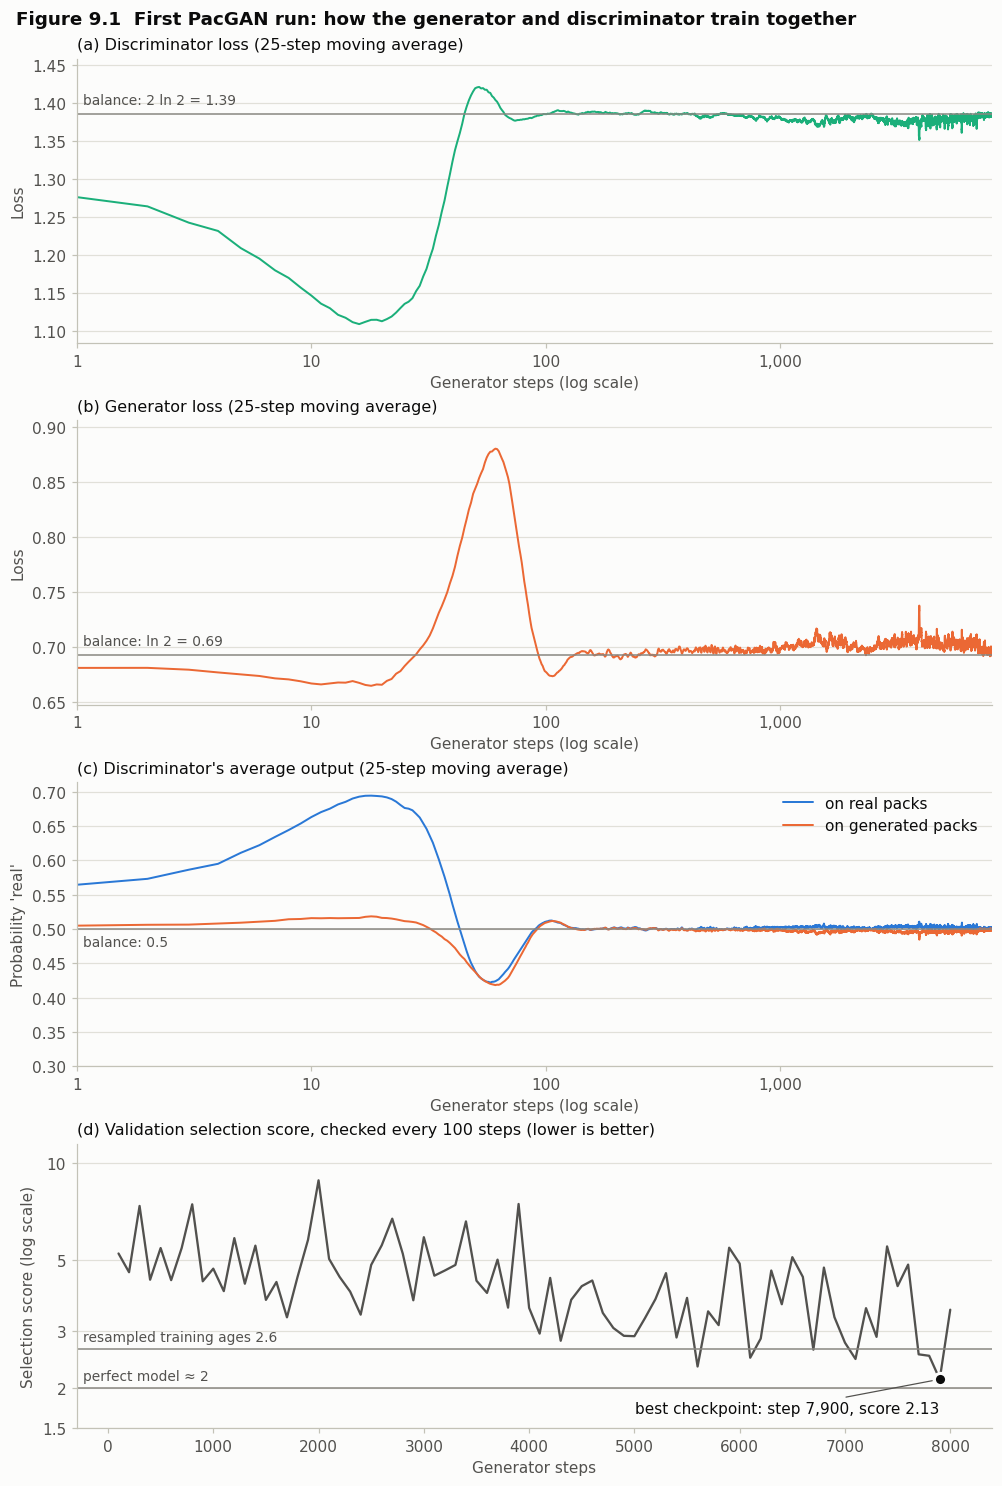

In [30]:
resampled_score = results.loc["Resampled training ages", "selection score"]


def plot_training(log, evals, best, title, path, window=25):
    """Four panels: (a) discriminator loss, (b) generator loss and (c) discriminator outputs, each a trailing
    moving average over `window` steps against log steps; (d) validation score with the best checkpoint."""
    roll = log.set_index("step").rolling(window, min_periods=1).mean()
    avg = f"{window}-step moving average"
    fig, axes = plt.subplots(4, 1, figsize=(9, 13.4), layout="constrained")

    x_pos = np.log10(roll.index) / np.log10(roll.index.max())   # position on the log step axis, 0 to 1

    def balance(ax, value, text, columns):
        """Gray reference line, labelled at the end (left or right) and on the side (above or below) that the
        curves leave most free. Call after setting the y-limits."""
        ax.axhline(value, color=C["muted"], linewidth=1)
        lo, hi = ax.get_ylim()
        near, far = 0.01 * (hi - lo), 0.09 * (hi - lo)   # where the label sits, as distance from the line

        def crowding(right, below):
            y = roll.loc[x_pos > 0.78 if right else x_pos < 0.22, columns].to_numpy()
            d = value - y if below else y - value
            return np.mean((d > near) & (d < far))

        right, below = min([(False, False), (False, True), (True, False), (True, True)], key=lambda c: crowding(*c))
        ax.annotate(text, (1.0 if right else 0.0, value), xycoords=("axes fraction", "data"),
                    xytext=(-4 if right else 4, -4 if below else 4), textcoords="offset points",
                    ha="right" if right else "left", va="top" if below else "bottom", color=C["ink2"], fontsize=9)

    for ax, column, color, value, text, name in [
            (axes[0], "D loss", C["disc"], 2 * np.log(2), "balance: 2 ln 2 = 1.39", "(a) Discriminator loss"),
            (axes[1], "G loss", C["generated"], np.log(2), "balance: ln 2 = 0.69", "(b) Generator loss")]:
        ax.plot(roll.index, roll[column], color=color, linewidth=1.3)
        lo, hi = min(roll[column].min(), value), max(roll[column].max(), value)
        ax.set_ylim(lo - 0.08 * (hi - lo), hi + 0.12 * (hi - lo))
        balance(ax, value, text, [column])
        ax.set_ylabel("Loss")
        ax.set_title(f"{name} ({avg})", fontsize=10.5, fontweight="normal")

    ax = axes[2]
    ax.plot(roll.index, roll["D(real)"], color=C["real"], linewidth=1.3, label="on real packs")
    ax.plot(roll.index, roll["D(fake)"], color=C["generated"], linewidth=1.3, label="on generated packs")
    d_out = roll[["D(real)", "D(fake)"]]
    ax.set_ylim(min(0.3, d_out.min().min() - 0.02), max(0.7, d_out.max().max() + 0.02))
    balance(ax, 0.5, "balance: 0.5", ["D(real)", "D(fake)"])
    ax.set_ylabel("Probability 'real'")
    ax.legend(loc="upper right")
    ax.set_title(f"(c) Discriminator's average output ({avg})", fontsize=10.5, fontweight="normal")

    ax = axes[3]
    ax.plot(evals["step"], evals["selection score"], color=C["ink2"], linewidth=1.5)
    ax.plot(best["step"], best["score"], "o", markersize=8, color=C["ink"], markeredgecolor=C["surface"],
            markeredgewidth=2)
    late = best["step"] > evals["step"].median()          # label on the side with more room
    ax.annotate(f"best checkpoint: step {best['step']:,}, score {best['score']:.2f}", (best["step"], best["score"]),
                xytext=(best["step"], 1.73), textcoords="data", ha="right" if late else "left", va="center",
                color=C["ink"], arrowprops=dict(arrowstyle="-", color=C["ink2"], linewidth=0.8, shrinkA=2, shrinkB=5))
    for value, text in [(2.0, "perfect model ≈ 2"),
                        (resampled_score, f"resampled training ages {resampled_score:.1f}")]:
        ax.axhline(value, color=C["muted"], linewidth=1)
        ax.annotate(text, (0.0, value), xycoords=("axes fraction", "data"), xytext=(4, 3),
                    textcoords="offset points", ha="left", va="bottom", color=C["ink2"], fontsize=9)
    y_top = evals["selection score"].max() * 1.3
    ticks = [t for t in [1.5, 2, 3, 5, 10, 20, 50, 100] if t <= y_top]
    ax.set_yscale("log")
    ax.set_yticks(ticks)
    ax.set_yticklabels([f"{t:g}" for t in ticks])
    ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_ylim(1.5, y_top)
    ax.set_ylabel("Selection score (log scale)")
    ax.set_xlabel("Generator steps")
    ax.set_title("(d) Validation selection score, checked every 100 steps (lower is better)",
                 fontsize=10.5, fontweight="normal")

    steps = int(log["step"].max())
    step_ticks = [t for t in [1, 10, 100, 1000, 10000] if t <= steps]
    for ax in axes[:3]:   # log steps: the fast first 100 steps and the long balance after them both show
        ax.set_xscale("log")
        ax.set_xlim(1, steps)
        ax.set_xticks(step_ticks)
        ax.set_xticklabels([f"{t:,}" for t in step_ticks])
        ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
        ax.set_xlabel("Generator steps (log scale)")

    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.savefig(path)
    plt.show()


plot_training(log, evals, best, "Figure 9.1  First PacGAN run: how the generator and discriminator train together",
              FIG_DIR / "fig9_1_first_run_training.png")

**Figure 9.1.** Training of the first PacGAN run (default settings).
- *(a)* The discriminator's loss and *(b)* the generator's loss, with their balance values as gray lines. The
  discriminator's balance is 2 ln 2 = 1.39 because its loss adds a term for real packs and one for generated
  packs, each ln 2 when it outputs 0.5. The generator's loss has only the generated term, so its balance is
  ln 2 = 0.69.
- *(c)* The discriminator's average probability that a pack is real, for real packs (blue) and generated packs
  (orange); 0.5 means it cannot tell them apart.
- *(d)* The validation selection score of the generator every 100 steps (log scale), with the best checkpoint
  marked. The gray lines show a perfect model (about 2) and the "resampled training ages" baseline.
- Panels (a)–(c) show 25-step moving averages (each point is the mean of the last 25 steps) against steps on a log
  scale, so the first 100 steps show next to the long balance that follows. Panel (d) uses a linear scale.

The log scale shows how training starts:
1. **The discriminator pulls ahead first.** Its loss falls to 1.11, because it scores real packs higher (up to
   0.69) while generated packs stay near 0.5.
2. **The generator catches up, and the discriminator overshoots.** Around steps 50–60 it can no longer tell the
   packs apart and scores both as more likely generated (about 0.42). Its loss rises just above balance, and the
   generator's loss peaks at 0.88.
3. **By about step 100 both networks are at balance**, and they stay close to it.

Because each point averages the 25 steps before it, these early changes appear up to about 12 steps after they
happen.

In [31]:
gan_ages = gan.generate(gan.z_eval)   # best checkpoint, same noise as during training
gan_name = f"PacGAN first run (step {best['step']:,})"
table = results.copy()
table.loc[gan_name] = pd.Series({"selection score": selection_score(compare(gan_ages, age_val)),
                                 **compare(gan_ages, age_val)})
fmt_table(table.loc[["Validation set (target)", "Noise floor (perfect model)", "Resampled training ages",
                     "KDE (h = 4.34, Silverman's rule)", gan_name]])

,selection score,Wasserstein (years),KS statistic,JS divergence,mean,std,5th pct,median,95th pct,% under 30,% at 89,% at 90
Validation set (target),—,—,—,—,63.59,17.87,28.00,66.00,89.00,6.15,5.36,0.00
Noise floor (perfect model),2.00,0.50,0.025,0.029,—,—,—,—,—,—,—,—
Resampled training ages,2.64,0.61,0.030,0.041,63.17,17.71,29.00,66.00,89.00,6.06,5.03,0.19
"KDE (h = 4.34, Silverman's rule)",3.64,0.69,0.040,0.065,63.10,18.06,28.00,66.00,89.00,5.92,1.10,4.04
"PacGAN first run (step 7,900)",2.13,0.41,0.019,0.037,63.49,17.91,27.00,66.00,89.00,6.23,4.33,0.78


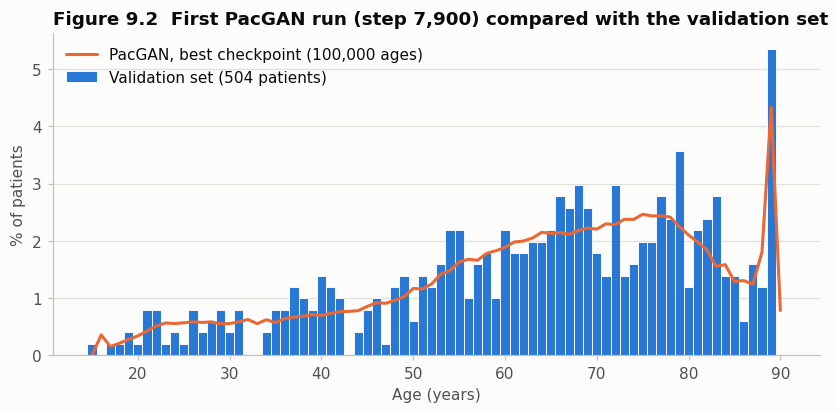

In [32]:
ages_axis = np.arange(min(age_val.min(), PREP["lo"]), max(age_val.max(), PREP["hi"]) + 1)
pct_at = lambda ages: 100 * np.array([np.mean(ages == a) for a in ages_axis])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(ages_axis, pct_at(age_val), width=1.0, color=C["real"], edgecolor=C["surface"], linewidth=0.6,
       label=f"Validation set ({n_val} patients)")
ax.plot(ages_axis, pct_at(gan_ages), color=C["generated"], label=f"PacGAN, best checkpoint ({N_GEN:,} ages)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("% of patients")
ax.legend(loc="upper left")
ax.set_title(f"Figure 9.2  First PacGAN run (step {best['step']:,}) compared with the validation set")
fig.savefig(FIG_DIR / "fig9_2_first_run_vs_validation.png")
plt.show()

**Figure 9.2.** Blue bars: share of validation patients at each age. Orange line: share of 100,000 ages generated by
the best checkpoint of the first run. The table above gives the matching scores next to the noise floor and two
baselines.

### 9.3 Findings from the first run

- **The two networks reach balance almost immediately and stay there.** After about 100 steps both losses sit at
  their balance values and the discriminator outputs about 0.5 for real and generated packs alike
  (Figure 9.1 a–c). That is what a working GAN looks like, but it also means the losses say nothing about quality.
- **Quality keeps changing underneath.** The validation score jumps between about 2 and 9 from one check to the
  next (Figure 9.1 d): the generator keeps drifting around the target and the discriminator keeps correcting it.
  On average the score improves during training, so later checkpoints tend to be better.
- **Best checkpoint (step 7,900): score 2.13**, close to a perfect model (2.0) and better than the resampled training
  ages (2.64): Wasserstein 0.41 years, KS 0.019, JS 0.037. No sign of mode collapse: spread 17.9 years (validation
  17.9) and 6.2% of patients under 30 (validation 6.2%).
- **The spike at 89 is mostly learned.** 4.3% of generated patients are 89 (validation 5.4%, training 5.0%) and 0.8%
  spill into 90 (validation 0%, training 0.2%). That is the option A risk, but far smaller than for the smoothing
  baselines (Figure 9.2; Silverman's KDE put 4.0% at 90).
- **Caveat.** 2.13 is the best of 80 checks on the same validation set, so it is optimistic; the test set will give
  the unbiased value. The best checkpoint also came at step 7,900 of 8,000, so longer training may help.

**For the search (Section 10):** train longer, use several seeds per setting (single runs move a lot), and compare
ways to calm the late-training drift, e.g. a lower learning rate.

## 10. Hyperparameter search (two stages)

The first run (Section 9) used default settings. Here we search for better ones. The networks are trained on the
training set only; the validation set only scores them (selection score, Section 9), and the test set stays locked.

**What is searched.** 24 settings: the default from Section 8 plus 23 drawn at random from 1458 combinations of hyperparameter values in the grid below. A random
sample covers the grid (1,458 combinations) better than a coarse full grid of the same size. The value ranges come
from the trial runs (Section 8): 1–2 discriminator steps never learned the spike, and a learning rate of 1e-3 caused
mode collapse, so both are left out. Every run trains for 12,000 steps (the first run's best checkpoint came at step
7,900 of 8,000) and keeps its best checkpoint, so the training length is chosen by the checkpoint selection.

**Two stages.** A single run is noisy: its score swings from check to check, and its best checkpoint is the best
of 120 checks, partly luck.
1. **Stage 1 (screening):** each of the 24 settings is trained once (seed 42) and ranked by its best-checkpoint
   score.
2. **Stage 2 (confirmation):** the 5 best settings are trained with 2 more seeds and ranked by the **median** of
   their 3 best-checkpoint scores.

**Choosing the winner (fixed before seeing the results).** Settings whose median is within 0.15 of the lowest
median are treated as tied, because differences that small are within the noise of a single score (Section 6).
Among tied settings the steadiest wins: the lowest median score over the last 2,000 steps of training. If that is
also within 0.15, the setting with the fewest network parameters wins.

**Saved results.** Each finished run is written to `results/search_runs.csv` (one row per run) and
`results/search_evals.csv` (its validation checks) straight away. An interrupted search resumes where it stopped,
and re-running the notebook loads the saved runs instead of training again (about 1.5 hours). To train again,
delete these two files.

In [33]:
SEARCH_STEPS = 12_000
GRID = {
    "lr": [1e-4, 2e-4, 5e-4],
    "d_steps": [3, 5, 8],
    "width": [64, 128, 256],
    "depth": [2, 3, 4],
    "latent": [4, 8, 16],
    "batch": [128, 256, 512],
    "lr_decay": ["none", "cosine"],
}
N_SETTINGS, N_FINALISTS = 24, 5
STAGE2_SEEDS = [SEED + 1, SEED + 2]
TIE = 0.15   # score differences below this count as ties


def n_params(cfg):
    """Total number of weights in the generator and the discriminator."""
    w, d = cfg["width"], cfg["depth"]
    hidden = (d - 1) * (w + 1) * w
    return (cfg["latent"] + 1) * w + hidden + (w + 1) + (PAC + 1) * w + hidden + (w + 1)


assert n_params(DEFAULT_CFG) == (build_generator(DEFAULT_CFG).count_params()
                                 + build_discriminator(DEFAULT_CFG).count_params())

search_rng = np.random.default_rng(SEED + 4)
settings = [dict(DEFAULT_CFG)]                 # setting 0 = the defaults of the first run
while len(settings) < N_SETTINGS:
    cfg = {k: v[search_rng.integers(len(v))] for k, v in GRID.items()} | {"dropout": 0.0}
    if cfg not in settings:
        settings.append(cfg)

settings_table = pd.DataFrame(settings)[list(GRID)]
settings_table["parameters"] = [n_params(c) for c in settings]
settings_table.index.name = "setting"
settings_table

,lr,d_steps,width,depth,latent,batch,lr_decay,parameters
setting,,,,,,,,
0,0.0002,5,128,3,8,256,none,68098
1,0.0002,8,64,2,8,128,none,9346
2,0.0002,3,256,4,4,512,cosine,397826
3,0.0005,8,64,3,8,512,cosine,17666
4,0.0005,5,128,3,16,512,none,69122
5,0.0002,8,64,4,16,128,cosine,26498
6,0.0001,3,128,2,4,512,none,34562
7,0.0001,8,256,2,4,128,none,134658
8,0.0002,5,128,2,8,128,cosine,35074


In [34]:
SEARCH_RUNS = RESULTS_DIR / "search_runs.csv"
SEARCH_EVALS = RESULTS_DIR / "search_evals.csv"
AT_BEST = ["Wasserstein (years)", "KS statistic", "JS divergence", "std", "% under 30", "% at 89", "% at 90"]


def load_runs():
    """Saved search runs; checks that each saved run used the setting it is filed under."""
    if not SEARCH_RUNS.exists():
        return pd.DataFrame(columns=["stage", "setting", "seed"])
    runs = pd.read_csv(SEARCH_RUNS)
    for _, r in runs.iterrows():
        cfg = settings[int(r["setting"])]
        assert all(r[k] == cfg[k] if isinstance(cfg[k], str) else np.isclose(r[k], cfg[k]) for k in GRID), \
            f"saved run of setting {r['setting']} does not match the current settings: delete {SEARCH_RUNS}"
    return runs


def run_search(stage, jobs):
    """Train each (setting, seed) job that is not saved yet; save each run as soon as it finishes."""
    for setting, seed in jobs:
        runs = load_runs()
        if ((runs["setting"] == setting) & (runs["seed"] == seed)).any():
            continue
        cfg = settings[setting]
        start = time.time()
        gan, log, evals, best = train_pacgan(cfg, seed=seed, steps=SEARCH_STEPS, report_every=0)
        at_best = evals.loc[evals["step"] == best["step"]].iloc[0]
        late = evals.loc[evals["step"] > SEARCH_STEPS - 2000, "selection score"]
        row = {"stage": stage, "setting": setting, "seed": seed, **{k: cfg[k] for k in GRID},
               "best score": best["score"], "best step": best["step"], "steadiness": late.median(),
               **{c: at_best[c] for c in AT_BEST}, "minutes": (time.time() - start) / 60}
        pd.DataFrame([row]).to_csv(SEARCH_RUNS, mode="a", header=not SEARCH_RUNS.exists(), index=False)
        (evals.assign(setting=setting, seed=seed)[["setting", "seed", "step", "selection score"]]
         .to_csv(SEARCH_EVALS, mode="a", header=not SEARCH_EVALS.exists(), index=False))
        print(f"stage {stage} | setting {setting:2d}, seed {seed} | best {best['score']:.2f} at step "
              f"{best['step']:,} | {row['minutes']:.1f} min", flush=True)
        del gan, log, evals
        tf.keras.backend.clear_session()

### 10.1 Stage 1: screening (24 settings, one seed each)

In [35]:
run_search(1, [(s, SEED) for s in range(N_SETTINGS)])
runs = load_runs()
stage1 = runs[runs["stage"] == 1].set_index("setting").sort_values("best score")
finalists = stage1.index[:N_FINALISTS].tolist()
print(f"Stage 1 took {stage1['minutes'].sum():.0f} minutes. Finalists (best first): {finalists}")
stage1[list(GRID) + ["best score", "best step", "steadiness", "% at 89", "% at 90", "minutes"]].round(
    {"best score": 2, "steadiness": 2, "% at 89": 1, "% at 90": 1, "minutes": 1})

Stage 1 took 62 minutes. Finalists (best first): [9, 0, 3, 22, 16]


,lr,d_steps,width,depth,latent,batch,lr_decay,best score,best step,steadiness,% at 89,% at 90,minutes
setting,,,,,,,,,,,,,
9,0.0001,3,256,4,8,256,cosine,2.11,9600,2.84,4.2,0.3,3.5
0,0.0002,5,128,3,8,256,none,2.13,7900,3.81,4.3,0.8,2.1
3,0.0005,8,64,3,8,512,cosine,2.20,7900,2.64,4.3,0.2,2.4
22,0.0002,5,256,3,4,128,none,2.21,11500,3.82,4.6,0.4,3.0
16,0.0001,8,128,3,4,256,cosine,2.24,5900,2.93,4.6,0.6,2.7
14,0.0005,8,128,2,8,256,none,2.25,10800,3.17,4.7,0.4,2.1
10,0.0005,8,128,4,16,512,none,2.26,6900,4.88,4.0,0.6,4.8
20,0.0002,8,128,2,4,256,cosine,2.31,7400,2.62,5.0,0.2,2.1
21,0.0005,3,256,3,8,512,cosine,2.36,3400,3.17,3.2,0.3,3.6


### 10.2 Stage 2: confirmation (the 5 best settings, two more seeds each)

In [36]:
run_search(2, [(s, seed) for s in finalists for seed in STAGE2_SEEDS])
runs = load_runs()
final_runs = runs[runs["setting"].isin(finalists)]
by_setting = final_runs.groupby("setting")
summary = pd.DataFrame({
    "stage-1 rank": {s: finalists.index(s) + 1 for s in finalists},
    "median best score": by_setting["best score"].median(),
    "lowest": by_setting["best score"].min(),
    "highest": by_setting["best score"].max(),
    "steadiness (median)": by_setting["steadiness"].median(),
    "parameters": {s: n_params(settings[s]) for s in finalists},
}).sort_values("median best score")

# The rule fixed in advance: ties within TIE on the median -> steadiest -> fewest parameters.
contenders = summary[summary["median best score"] <= summary["median best score"].min() + TIE]
steadiest = contenders[contenders["steadiness (median)"] <= contenders["steadiness (median)"].min() + TIE]
chosen = int(steadiest.sort_values("parameters").index[0])
summary["chosen"] = np.where(summary.index == chosen, "✓", "")
summary.to_csv(RESULTS_DIR / "search_summary.csv")

chosen_cfg = settings[chosen]
print(f"Stage 2 took {runs.loc[runs['stage'] == 2, 'minutes'].sum():.0f} minutes.")
print(f"Tied with the best median: settings {contenders.index.tolist()}; chosen: setting {chosen} by comparing steadiness and size")
print("Chosen setting:", {k: chosen_cfg[k] for k in GRID})
print(f"Stage-1 rank vs stage-2 rank (Spearman): "
      f"{stats.spearmanr(summary['stage-1 rank'], np.arange(1, len(summary) + 1)).statistic:.2f}")
summary.round(2)

Stage 2 took 27 minutes.
Tied with the best median: settings [16, 3, 9]; chosen: setting 3 by comparing steadiness and size
Chosen setting: {'lr': 0.0005, 'd_steps': 8, 'width': 64, 'depth': 3, 'latent': 8, 'batch': 512, 'lr_decay': 'cosine'}
Stage-1 rank vs stage-2 rank (Spearman): -0.30


,stage-1 rank,median best score,lowest,highest,steadiness (median),parameters,chosen
16,5,2.18,2.18,2.24,2.69,67586,
3,3,2.24,2.20,2.29,2.77,17666,✓
9,1,2.25,2.11,2.27,2.84,398850,
0,2,2.41,2.13,2.55,3.64,68098,
22,4,2.51,2.21,2.68,4.33,266242,


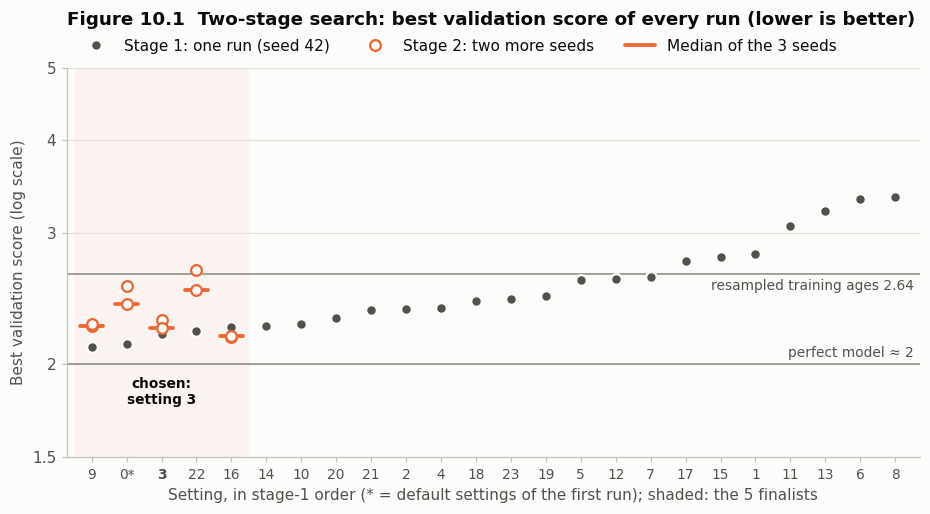

In [37]:
order = stage1.index.tolist()               # settings in stage-1 order (best first)
x_of = {s: i for i, s in enumerate(order)}
y_all = pd.concat([runs["best score"], pd.Series([2.0, resampled_score])])
y_lo, y_hi = 1.5, max(5, y_all.max() * 1.15)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot([x_of[s] for s in order], stage1.loc[order, "best score"], "o", markersize=7, color=C["ink2"],
        markeredgecolor=C["surface"], markeredgewidth=1.5, label="Stage 1: one run (seed 42)", zorder=3)
stage2 = runs[runs["stage"] == 2]
ax.plot([x_of[s] for s in stage2["setting"]], stage2["best score"], "o", markersize=7,
        markerfacecolor=C["surface"], markeredgecolor=C["generated"], markeredgewidth=1.5,
        label="Stage 2: two more seeds", zorder=3)
for i, s in enumerate(summary.index):
    xs = x_of[s]
    ax.plot([xs - 0.32, xs + 0.32], [summary.loc[s, "median best score"]] * 2, color=C["generated"],
            linewidth=2.5, label="Median of the 3 seeds" if i == 0 else None, zorder=2)
ax.annotate(f"chosen:\nsetting {chosen}", (x_of[chosen], 2.0), xytext=(0, -8), textcoords="offset points",
            ha="center", va="top", color=C["ink"], fontsize=9, fontweight="semibold")
for value, text, below in [(2.0, "perfect model ≈ 2", False),
                           (resampled_score, f"resampled training ages {resampled_score:.2f}", True)]:
    ax.axhline(value, color=C["muted"], linewidth=1, zorder=1)
    ax.annotate(text, (1.0, value), xycoords=("axes fraction", "data"), xytext=(-4, -3 if below else 3),
                textcoords="offset points", ha="right", va="top" if below else "bottom", color=C["ink2"],
                fontsize=9)
ax.axvspan(-0.5, N_FINALISTS - 0.5, color=to_rgba(C["generated"], 0.06), linewidth=0, zorder=0)
ax.set_yscale("log")
ticks = [t for t in [1.5, 2, 3, 4, 5, 7, 10, 20, 50] if y_lo <= t <= y_hi]
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:g}" for t in ticks])
ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_ylim(y_lo, y_hi)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{s}" + ("*" if s == 0 else "") for s in order], fontsize=9)
ax.get_xticklabels()[x_of[chosen]].set_fontweight("bold")
ax.set_xlim(-0.7, len(order) - 0.3)
ax.set_xlabel(f"Setting, in stage-1 order (* = default settings of the first run); "
              f"shaded: the {N_FINALISTS} finalists")
ax.set_ylabel("Best validation score (log scale)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax.set_title("Figure 10.1  Two-stage search: best validation score of every run (lower is better)", pad=28)
fig.savefig(FIG_DIR / "fig10_1_search_scores.png")
plt.show()

**Figure 10.1.** Every run of the search. Settings are ordered by their stage-1 score (best on the left), with
the setting number below each. Gray dots: the single stage-1 run of each setting (seed 42). Shaded: the 5 finalists.
Orange circles: their two extra stage-2 runs (seeds 43 and 44); orange bars: the median of the three runs, which
decides the winner. The chosen setting has a bold number and is labelled below the 2.0 line. Gray lines: a perfect
model (about 2) and the resampled-training-ages baseline (Section 6.4). The gap between a finalist's three runs
shows how much of a single run's score is seed luck.

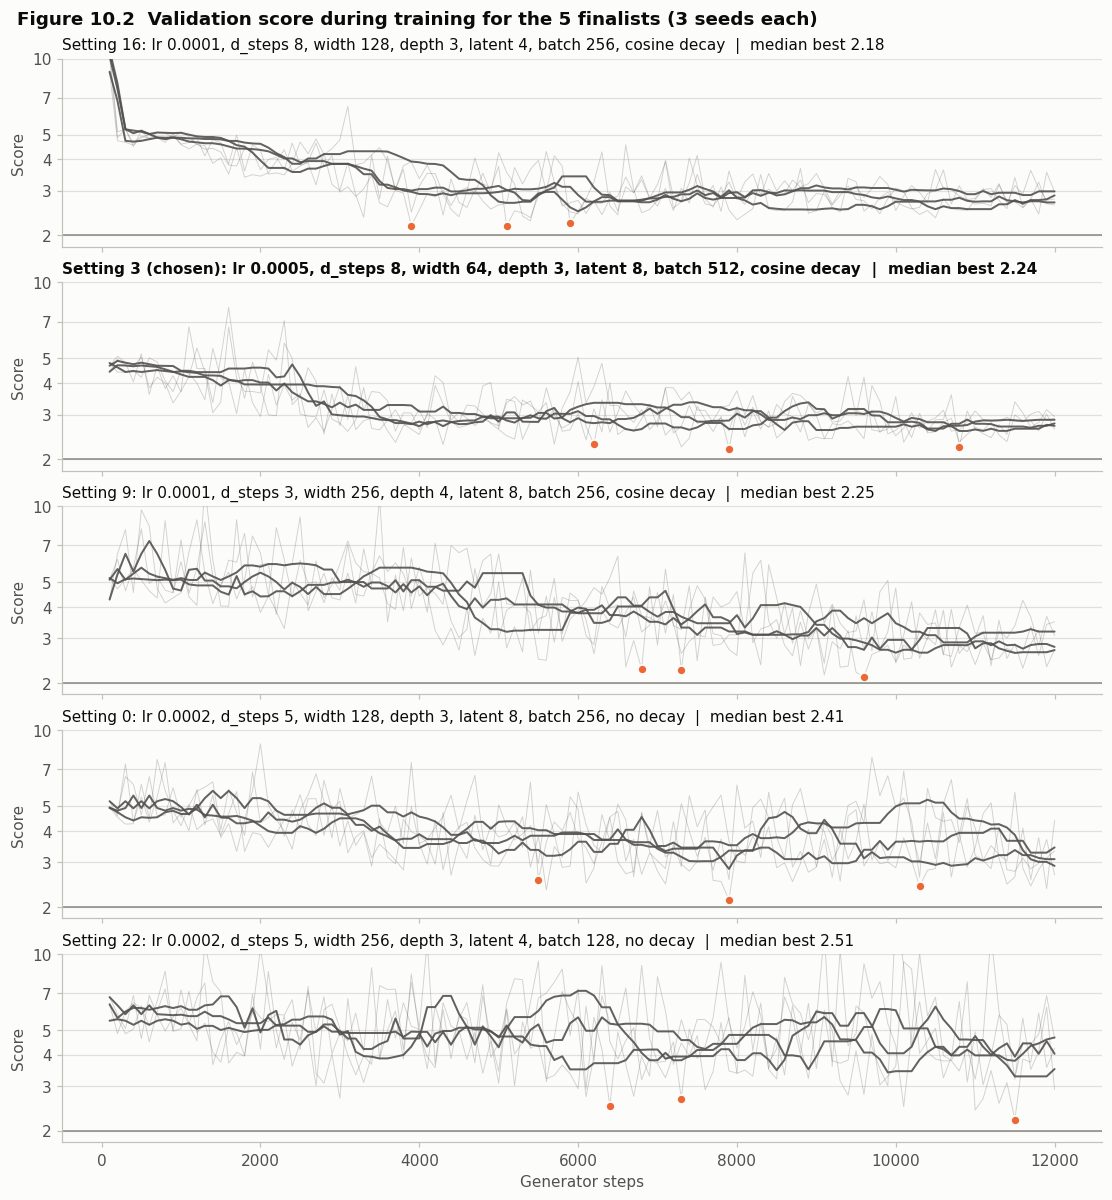

In [38]:
search_evals = pd.read_csv(SEARCH_EVALS)
fig, axes = plt.subplots(len(summary), 1, figsize=(10, 2.0 * len(summary) + 0.8), sharex=True, sharey=True,
                         layout="constrained")
for ax, s in zip(axes, summary.index):
    for seed in sorted(final_runs.loc[final_runs["setting"] == s, "seed"]):
        e = search_evals[(search_evals["setting"] == s) & (search_evals["seed"] == seed)].sort_values("step")
        smooth = e["selection score"].rolling(10, min_periods=1).median()
        ax.plot(e["step"], e["selection score"], color=C["ink2"], linewidth=0.6, alpha=0.25)
        ax.plot(e["step"], smooth, color=C["ink2"], linewidth=1.3, alpha=0.9)
        b = e.loc[e["selection score"].idxmin()]
        ax.plot(b["step"], b["selection score"], "o", markersize=6, color=C["generated"],
                markeredgecolor=C["surface"], markeredgewidth=1.2)
    ax.axhline(2.0, color=C["muted"], linewidth=1)
    cfg = settings[s]
    decay = "cosine decay" if cfg["lr_decay"] == "cosine" else "no decay"
    ax.set_title(f"Setting {s}{' (chosen)' if s == chosen else ''}: lr {cfg['lr']:g}, d_steps {cfg['d_steps']}, "
                 f"width {cfg['width']}, depth {cfg['depth']}, latent {cfg['latent']}, batch {cfg['batch']}, "
                 f"{decay}  |  median best {summary.loc[s, 'median best score']:.2f}",
                 fontsize=10, fontweight="semibold" if s == chosen else "normal")
    ax.set_yscale("log")
    ax.set_ylabel("Score")
ticks3 = [2, 3, 4, 5, 7, 10]
axes[0].set_yticks(ticks3)
axes[0].set_yticklabels([f"{t:g}" for t in ticks3])
for ax in axes:
    ax.yaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_ylim(1.8, 10)
axes[-1].set_xlabel("Generator steps")
fig.suptitle(f"Figure 10.2  Validation score during training for the {N_FINALISTS} finalists "
             f"({1 + len(STAGE2_SEEDS)} seeds each)", x=0.01,
             ha="left", fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig10_2_finalists_training.png")
plt.show()

**Figure 10.2.** Validation selection score during training for each finalist, best median first, with the
chosen setting's title in bold. There are three runs (seeds) per panel. Faint lines: the raw score at each check
(every 100 steps). Dark lines: the same scores smoothed with a running median over 10 checks (1,000 steps), to show
the trend through the check-to-check swings. Orange dots: each run's best checkpoint, the lowest raw score. The
dots sit well below the dark lines because the best checkpoint is the luckiest dip of 120 checks (Section 10.3).
Gray line: a perfect model (about 2). Log scale; the first checks, above 10, are cut off.

### 10.3 Findings

- **Cost.** 34 training runs took 89 minutes on CPU: 24 in stage 1 (62 min) and 10 in stage 2 (27 min).
- **What separates good settings from bad (stage-1 table, Section 10.1).** Best stage-1 scores range from 2.11
  to 3.35.
  - The four worst runs (settings 8, 6, 13 and 11; 3.06–3.35) all have depth 2, and they put only 1.0–1.3% of ages
    at 89 against 5.4% in validation. They never learned the spike.
  - Depth 2 has the worst median, 2.81 against 2.37 for depth 3 or 4.
  - Width 64 and batch 128 also have high medians (2.75 each), but many of those runs also have depth 2, so the
    effects are mixed together.
  - Learning rate, discriminator steps, latent size and learning-rate decay show no clear pattern.
- **One run per setting is not enough (stage 2, Figure 10.1).** The stage-1 leader, setting 9 (2.11), scored 2.25
  and 2.27 with the two new seeds. The defaults, 2.13 in the first run (Section 9), scored 2.55 and 2.41, and
  setting 22 went from 2.21 to 2.68 and 2.51. Settings partly reached the top of stage 1 by getting a lucky seed, so
  their stage-1 scores were too good. Among the 5 finalists, the stage-1 order does not predict the stage-2 order
  (Spearman correlation −0.30).
- **The chosen setting, by the rule fixed in advance: setting 3.**
  - Settings 16, 3 and 9 have medians within 0.15 of the best (2.18, 2.24 and 2.25), so they tie.
  - Their steadiness also ties within 0.15 (2.69, 2.77 and 2.84), so the rule picks the smallest network, setting
    3, with 17,666 weights against 67,586 for setting 16 and 398,850 for setting 9.
  - Setting 3 uses learning rate 5e-4 with cosine decay, 8 discriminator updates per generator update, 3 hidden
    layers of 64 units, latent size 8 and batch 512.
  - Its three runs agree closely: 2.20, 2.29 and 2.24.
- **Gain over the defaults: modest.** The median best score drops from 2.41 to 2.24, less than the spread of the
  defaults' own three runs (2.13–2.55). The clearer gains are steadiness and size. Over the last 2,000 steps the
  chosen setting scores about 2.6–2.8, against 3.1–3.8 for the defaults (Figure 10.2), with a quarter of the
  weights.
- **The best validation score is optimistic (Figure 10.2).**
  - A run's best checkpoint is the lowest of 120 checks against the same 504 validation ages, so part of its low
    score is luck: setting 3's best checkpoints score 2.20–2.29, while its typical late check scores 2.6–2.8.
  - The same caveat applies to the baselines. 17 of the 24 stage-1 runs beat the resampled training ages (2.64) on
    validation, but the GAN's score is a best of 120 and the baseline's is a single score.
  - An honest score needs ages that played no part in any choice. That is the test set, used once in the final
    evaluation, where the GAN should score above 2.2.

## 11. Final model and how the two networks coordinate

**The final model** uses the setting chosen in Section 10 (setting 3), trained with seed 42.
- Seed 42 gave the best of that setting's three runs on validation: 2.20, against 2.24 for seed 44 and 2.29 for
  seed 43.
- The three seeds are within 0.09 of each other, which is within the noise of a single score, so the choice of
  seed barely matters.
- Training is deterministic, so this run reproduces the stage-1 search run exactly, and the code checks that.
- Data use is unchanged: the networks train on the training set, the validation set only picks the best
  checkpoint, and the test set stays locked until Section 12.

This time the weights of both networks are also kept at every check (every 100 steps). That lets us look inside
the training and see how the discriminator steers the generator (Section 11.1).

In [39]:
chosen_runs = runs[runs["setting"] == chosen].set_index("seed")["best score"].sort_values()
FINAL_SEED = int(chosen_runs.index[0])   # the chosen setting's best run on validation
print(f"Setting {chosen}, best validation score by seed: "
      + ", ".join(f"seed {s} {v:.2f}" for s, v in chosen_runs.items()) + f"  ->  final seed {FINAL_SEED}\n")

final_gan, final_log, final_evals, final_best = train_pacgan(chosen_cfg, seed=FINAL_SEED, steps=SEARCH_STEPS,
                                                             report_every=2000, keep_history=True)
saved = runs[(runs["setting"] == chosen) & (runs["seed"] == FINAL_SEED)].iloc[0]
assert final_best["step"] == saved["best step"] and abs(final_best["score"] - saved["best score"]) < 1e-9, \
    "the final run does not reproduce its search run"
final_evals.to_csv(RESULTS_DIR / "final_model_validation_checks.csv", index=False)

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
final_gan.G.save(MODEL_DIR / "final_generator.keras")
print(f"\nBest checkpoint: step {final_best['step']:,}, selection score {final_best['score']:.2f} "
      f"(identical to the search run). Generator saved to {MODEL_DIR / 'final_generator.keras'}.")

Setting 3, best validation score by seed: seed 42 2.20, seed 44 2.24, seed 43 2.29  ->  final seed 42



step  2,000 | D loss 1.408  G loss 0.703 | score  2.95, best 2.95 at step 2,000 | 24s


step  4,000 | D loss 1.390  G loss 0.702 | score  2.61, best 2.57 at step 2,800 | 47s


step  6,000 | D loss 1.378  G loss 0.699 | score  3.03, best 2.57 at step 2,800 | 69s


step  8,000 | D loss 1.386  G loss 0.688 | score  3.16, best 2.20 at step 7,900 | 93s


step 10,000 | D loss 1.387  G loss 0.696 | score  2.60, best 2.20 at step 7,900 | 121s


step 12,000 | D loss 1.383  G loss 0.691 | score  2.62, best 2.20 at step 7,900 | 144s

Best checkpoint: step 7,900, selection score 2.20 (identical to the search run). Generator saved to models/final_generator.keras.


In [40]:
final_gan.G.summary()   # weights of the best checkpoint; the layers are the same at every step
final_gan.D.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise (InputLayer)              │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_18 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ age_in_model_units (Dense)      │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,961 (35.00 KB)

 Trainable params: 8,961 (35.00 KB)

 Non-trainable params: 0 (0.00 B)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pack_of_ages (InputLayer)       │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_21 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_22 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_23 (LeakyReLU)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,705 (34.00 KB)

 Trainable params: 8,705 (34.00 KB)

 Non-trainable params: 0 (0.00 B)

**The two networks of the final model.** Both are small fully connected networks: 3 hidden layers of 64 units,
each followed by a LeakyReLU activation (slope 0.2 for negative inputs).
- **Generator:** it turns 8 random numbers (the noise) into one age, in scaled units: the training mean and
  spread from Section 5. `generate` converts that back to whole years. It has 8,961 weights.
- **Discriminator:** it reads a pack of 4 ages and returns one number, the logit of its probability that the pack
  is real. It has 8,705 weights.
- Together they have 17,666 weights, the count the Section 10 tie rule used.

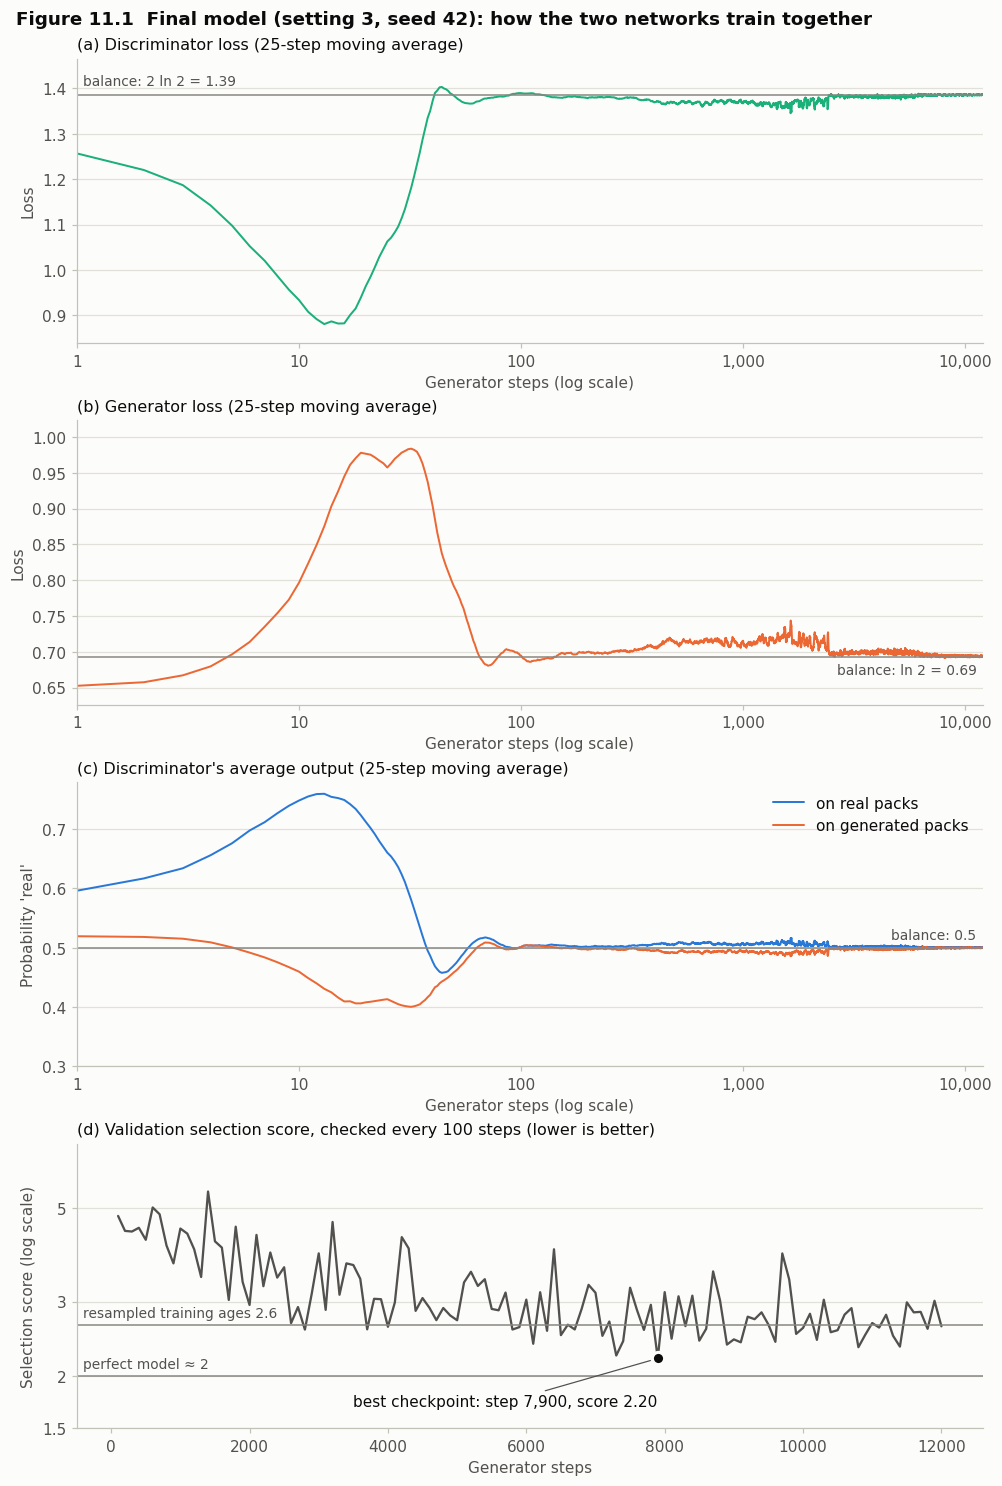

In [41]:
plot_training(final_log, final_evals, final_best,
              f"Figure 11.1  Final model (setting {chosen}, seed {FINAL_SEED}): how the two networks train together",
              FIG_DIR / "fig11_1_final_model_training.png")

**Figure 11.1.** Training of the final model, drawn the same way as Figure 9.1.
- *(a)* The discriminator's loss and *(b)* the generator's loss. *(c)* The discriminator's average probability that
  a pack is real, for real packs (blue) and generated packs (orange). All three are 25-step moving averages against
  steps on a log scale, with their balance values as gray lines.
- In this setting the discriminator is updated 8 times for every generator update; (a) and (c) show its last
  update of each step.
- *(d)* The validation selection score every 100 steps (log scale), with the best checkpoint marked. The gray
  lines show a perfect model (about 2) and the "resampled training ages" baseline.

What the panels show:
1. **The start is sharper than in the first run.** The discriminator's loss falls to 0.88 by about step 13, as it
   scores real packs up to 0.76 and generated packs down to 0.40. So here the generator's loss rises while the
   discriminator is ahead, to 0.98. Both networks are at balance by about step 100.
2. **Just after step 2,400 all three curves move closer to their balance values and become steadier.** The
   discriminator's edge (real minus generated) shrinks from 0.013 on average to 0.004 (Section 11.2). This is the
   moment the generator learns the spike at 89 (Section 11.1).

In [42]:
final_ages = final_gan.generate(final_gan.z_eval)   # best checkpoint, same noise as during training
final_name = f"Final PacGAN (setting {chosen}, seed {FINAL_SEED}, step {final_best['step']:,})"
table.loc[final_name] = pd.Series({"selection score": selection_score(compare(final_ages, age_val)),
                                   **compare(final_ages, age_val)})
fmt_table(table.loc[["Validation set (target)", "Noise floor (perfect model)", "Resampled training ages",
                     "KDE (h = 4.34, Silverman's rule)", gan_name, final_name]])

,selection score,Wasserstein (years),KS statistic,JS divergence,mean,std,5th pct,median,95th pct,% under 30,% at 89,% at 90
Validation set (target),—,—,—,—,63.59,17.87,28.00,66.00,89.00,6.15,5.36,0.00
Noise floor (perfect model),2.00,0.50,0.025,0.029,—,—,—,—,—,—,—,—
Resampled training ages,2.64,0.61,0.030,0.041,63.17,17.71,29.00,66.00,89.00,6.06,5.03,0.19
"KDE (h = 4.34, Silverman's rule)",3.64,0.69,0.040,0.065,63.10,18.06,28.00,66.00,89.00,5.92,1.10,4.04
"PacGAN first run (step 7,900)",2.13,0.41,0.019,0.037,63.49,17.91,27.00,66.00,89.00,6.23,4.33,0.78
"Final PacGAN (setting 3, seed 42, step 7,900)",2.20,0.45,0.021,0.037,63.56,17.98,28.00,67.00,88.00,5.83,4.33,0.23


### 11.1 Inside the training: what the discriminator tells the generator

Figure 11.1 shows the two networks in balance, but not what passes between them. The discriminator's only
message to the generator is its score: the generator's gradient moves each generated age uphill, toward ages the
discriminator finds more "real". So at each check we reload both networks' saved weights and ask two questions:

1. **Which ages does the generator make?** 100,000 ages from the fixed noise, compared with the training ages it
   learns from.
2. **How does the discriminator judge each age?** The age is put in a pack with 3 random training ages, and the
   discriminator's probability "real" is averaged over 500 such packs and all 4 positions in the pack. Each probe
   age is spread over its year, like the real ages. We compare this with the discriminator's response to a typical
   real age; the difference is its **push** at that age.

If the two networks coordinate as intended, the push is **positive** where the generator makes **too few** ages
and **negative** where it makes **too many**. That is what moves the generator toward the training distribution.

In [43]:
AGES = np.arange(PREP["lo"], PREP["hi"] + 1)   # 16 ... 90, the same ages as `grid` in Section 7
I89 = int(np.flatnonzero(AGES == 89)[0])
share = lambda ages: 100 * np.bincount(np.asarray(ages) - PREP["lo"], minlength=len(AGES)) / len(ages)
train_share = share(age_train)

G_view, D_view = build_generator(chosen_cfg), build_discriminator(chosen_cfg)   # copies for the saved weights
view_rng = np.random.default_rng(SEED + 6)
N_CONTEXT = 500
context = scale(dequantize(view_rng.choice(age_train, size=(N_CONTEXT, PAC - 1)), view_rng))
probe = scale(AGES[:, None] + view_rng.uniform(-0.5, 0.5, N_CONTEXT)[None, :])   # (ages, packs)


def generated_share(step):
    """% of the 100,000 generated ages at each whole year, with the generator saved at `step`."""
    G_view.set_weights(final_gan.history[step][0])
    return share(to_whole_years(unscale(G_view(final_gan.z_eval, training=False).numpy().ravel())))


def disc_response(step):
    """Discriminator saved at `step`: mean probability 'real' of a pack holding each age plus 3 training ages."""
    D_view.set_weights(final_gan.history[step][1])
    out = np.zeros(len(AGES))
    for slot in range(PAC):
        packs = np.empty((len(AGES), N_CONTEXT, PAC), np.float32)
        packs[:, :, [k for k in range(PAC) if k != slot]] = context[None]
        packs[:, :, slot] = probe
        p = tf.sigmoid(D_view(packs.reshape(-1, PAC), training=False)).numpy()
        out += p.reshape(len(AGES), N_CONTEXT).mean(axis=1)
    return out / PAC


steps_kept = sorted(final_gan.history)
gen_share = np.array([generated_share(s) for s in steps_kept])      # (checks, ages)
d_resp = np.array([disc_response(s) for s in steps_kept])
d_typical = d_resp @ (train_share / 100)                            # response to a typical real age
d_push = d_resp - d_typical[:, None]                                # > 0: looks more real than typical

k_peak = int(np.argmax(d_push[:, I89]))   # check where the push at 89 is strongest
peak_step = steps_kept[k_peak]
k_best = steps_kept.index(final_best["step"])
print(f"Strongest push at 89: step {peak_step:,}, +{d_push[k_peak, I89]:.3f}, while the generator put "
      f"{gen_share[k_peak, I89]:.1f}% of ages at 89 (training {train_share[I89]:.1f}%). One check later: "
      f"{gen_share[k_peak + 1, I89]:.1f}% at 89, push {d_push[k_peak + 1, I89]:+.3f}.")
print(f"Range of the discriminator's response across ages: step 2,000 {np.ptp(d_resp[steps_kept.index(2000)]):.3f},"
      f" best checkpoint {np.ptp(d_resp[k_best]):.3f}")

# Averages over three phases of training (the first 100 steps, before the networks settle, are left out).
phases = {}
for lo, hi in [(100, peak_step), (peak_step, 6000), (6000, SEARCH_STEPS)]:
    in_log = (final_log["step"] > lo) & (final_log["step"] <= hi)
    ck = (np.array(steps_kept) > lo) & (np.array(steps_kept) <= hi)
    phases[f"steps {lo + 1:,}-{hi:,}"] = {
        "D(real)": final_log.loc[in_log, "D(real)"].mean(), "D(fake)": final_log.loc[in_log, "D(fake)"].mean(),
        "% at 89": gen_share[ck, I89].mean(), "push at 89": d_push[ck, I89].mean()}
pd.DataFrame(phases).T.round(3)

Strongest push at 89: step 2,400, +0.154, while the generator put 0.2% of ages at 89 (training 5.0%). One check later: 2.2% at 89, push -0.004.
Range of the discriminator's response across ages: step 2,000 0.094, best checkpoint 0.017


,D(real),D(fake),% at 89,push at 89
"steps 101-2,400",0.506,0.493,1.155,0.051
"steps 2,401-6,000",0.502,0.498,2.934,0.008
"steps 6,001-12,000",0.500,0.500,4.102,-0.000


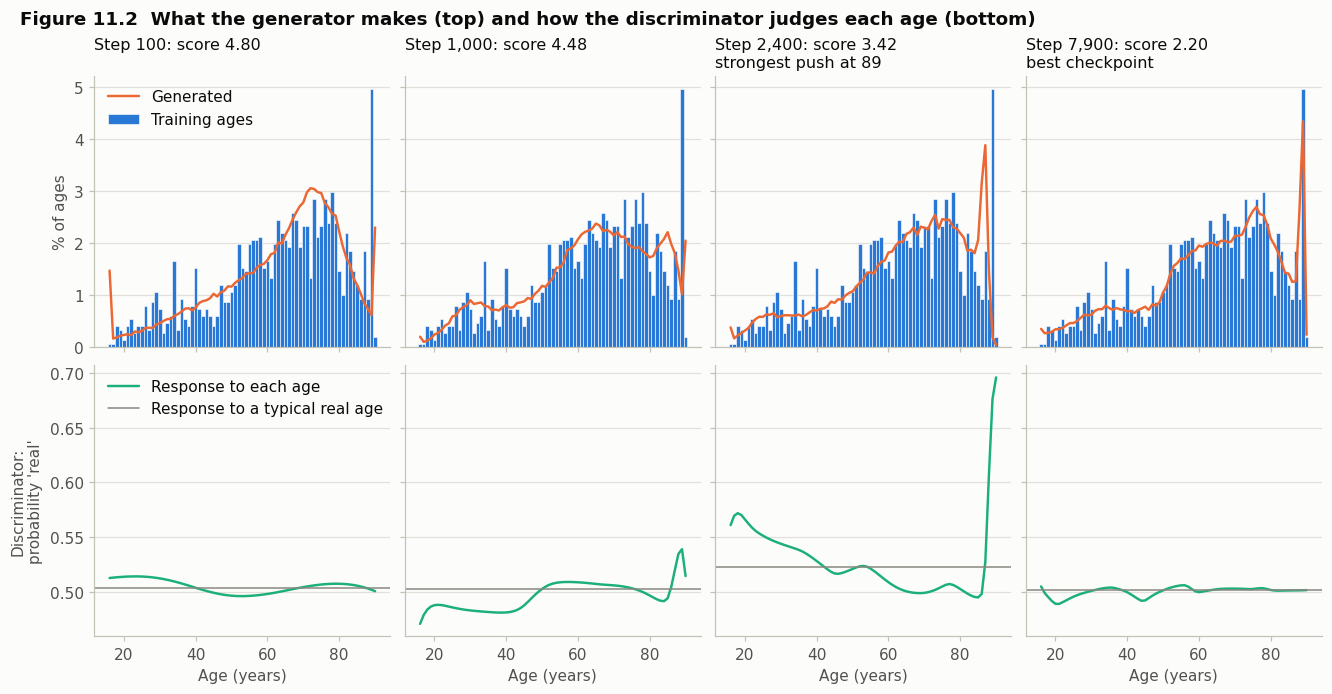

In [44]:
SNAP = [100, 1000, peak_step, final_best["step"]]
notes = {peak_step: "strongest push at 89", final_best["step"]: "best checkpoint"}
fig, axes = plt.subplots(2, len(SNAP), figsize=(12, 6.2), sharex=True, sharey="row", layout="constrained")
for j, s in enumerate(SNAP):
    k = steps_kept.index(s)
    ax = axes[0, j]
    ax.bar(AGES, train_share, width=1.0, color=C["real"], edgecolor=C["surface"], linewidth=0.4,
           label="Training ages")
    ax.plot(AGES, gen_share[k], color=C["generated"], linewidth=1.6, label="Generated")
    score = final_evals.loc[final_evals["step"] == s, "selection score"].iloc[0]
    ax.set_title(f"Step {s:,}: score {score:.2f}" + (f"\n{notes[s]}" if s in notes else "\n"),
                 fontsize=10.5, fontweight="normal")
    ax = axes[1, j]
    ax.plot(AGES, d_resp[k], color=C["disc"], linewidth=1.6, label="Response to each age")
    ax.axhline(d_typical[k], color=C["muted"], linewidth=1, label="Response to a typical real age")
    ax.set_xlabel("Age (years)")
axes[0, 0].set_ylabel("% of ages")
axes[1, 0].set_ylabel("Discriminator:\nprobability 'real'")
axes[0, 0].legend(loc="upper left")
axes[1, 0].legend(loc="upper left")
fig.suptitle("Figure 11.2  What the generator makes (top) and how the discriminator judges each age (bottom)",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig11_2_generator_vs_discriminator_snapshots.png")
plt.show()

**Figure 11.2.** Four moments in the training of the final model, one per column: the start (step 100), early
training (step 1,000), the check where the discriminator pushes hardest toward age 89, and the best checkpoint.
*Top row:* share of training ages at each age (blue bars) and of 100,000 ages from the generator at that moment
(orange line); the score is the validation selection score. *Bottom row:* the discriminator at the same moment. The
aqua line is its average probability "real" for a pack holding that age and 3 random training ages; the gray line
is its response to a typical real age. Where the aqua line is above the gray line, the discriminator finds that
age more real than typical: the generator makes too few of it and is pushed to make more.

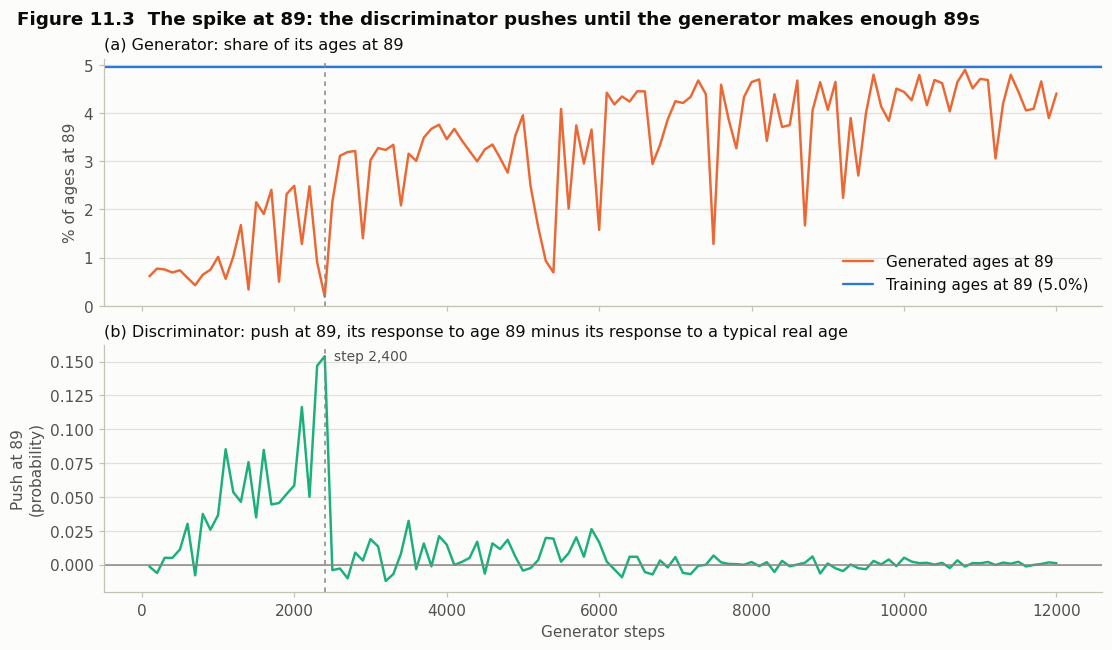

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, layout="constrained")
ax = axes[0]
ax.plot(steps_kept, gen_share[:, I89], color=C["generated"], linewidth=1.6, label="Generated ages at 89")
ax.axhline(train_share[I89], color=C["real"], linewidth=1.5, label=f"Training ages at 89 ({train_share[I89]:.1f}%)")
ax.set_ylim(0, None)
ax.set_ylabel("% of ages at 89")
ax.legend(loc="lower right")
ax.set_title("(a) Generator: share of its ages at 89", fontsize=10.5, fontweight="normal")
ax = axes[1]
ax.plot(steps_kept, d_push[:, I89], color=C["disc"], linewidth=1.6)
ax.axhline(0, color=C["muted"], linewidth=1)
ax.set_ylabel("Push at 89\n(probability)")
ax.set_xlabel("Generator steps")
ax.set_title("(b) Discriminator: push at 89, its response to age 89 minus its response to a typical real age",
             fontsize=10.5, fontweight="normal")
for ax in axes:
    ax.axvline(peak_step, color=C["muted"], linewidth=1, linestyle=(0, (3, 3)))
axes[1].annotate(f"step {peak_step:,}", (peak_step, d_push[k_peak, I89]), xytext=(6, 0), textcoords="offset points",
                 ha="left", va="center", color=C["ink2"], fontsize=9)
fig.suptitle("Figure 11.3  The spike at 89: the discriminator pushes until the generator makes enough 89s",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig11_3_spike_at_89.png")
plt.show()

**Figure 11.3.** The exchange between the two networks at age 89, the eICU "> 89" spike, over all 120 checks.
*(a)* Share of the generator's 100,000 ages that fall at 89 (orange) and the share in the training set (blue).
*(b)* The discriminator's push at 89 (aqua): its probability "real" for a pack holding 89 and 3 random training
ages, minus the same for a typical real age. Above 0 means 89 looks more real than typical, so the generator is
pushed to make more 89s. The dashed line marks the check with the strongest push.

### 11.2 Findings

- **The final model reproduces its search run exactly.** Its best checkpoint is at step 7,900, with validation
  score 2.20: Wasserstein 0.45 years, KS 0.021, JS 0.037.
  - It puts 4.3% of ages at 89 (validation 5.4%, training 5.0%) and 0.2% at 90 (training 0.2%, validation 0%).
    The first run spilled 0.8% into 90.
  - There is no sign of mode collapse: the spread is 18.0 years (validation 17.9), and 5.8% of ages are under 30
    (validation 6.2%).
- **Its validation score is slightly worse than the first run's: 2.20 against 2.13.**
  - That is expected. The first run's 2.13 was its seed's luck (the other seeds scored 2.41 and 2.55, Section 10),
    while setting 3 scored 2.20–2.29 on all three seeds.
  - Both numbers are optimistic, because each is the best of 120 checks. The test set (Section 12) gives the
    honest number.
- **The discriminator finds the missing spike first (Figures 11.2 and 11.3).**
  - Early on, the generator puts about 1% of ages at 89 and too many at 80–87. The discriminator scores 89 as more
    real than a typical real age and 80–87 as less real.
  - Its push at 89 grows until step 2,400, where it peaks at +0.15. At that check the generator had slid its spike
    down to 86–87, with only 0.2% at 89.
  - One check later the generator puts 2.2% at 89, and the push at 89 drops to about zero.
- **The same moment shows in the discriminator's outputs (Figure 11.1 c).**
  - Until step 2,400 the discriminator keeps a small edge: on average 0.506 for real packs against 0.493 for
    generated ones. Once the generator has its spike, the edge shrinks to 0.502 against 0.498, and after step
    6,000 it is gone (0.500 against 0.500).
  - A small positive push at 89 remains until step 6,000 (+0.008 on average), while the generator's share at 89
    keeps climbing: 2.9% on average from step 2,401 to 6,000, and 4.1% after that.
- **At the best checkpoint the discriminator's response is flat (Figure 11.2, last column).**
  - Its range across ages shrinks from 0.09 at step 2,000 to 0.02 at the best checkpoint: once the generator is
    close, there is little left to flag.
  - This flat response is the equilibrium a GAN aims for. It is also why the losses cannot tell good checkpoints
    from bad ones, and why the validation checks are needed.

## 12. Final evaluation on the test set (opened once)

Every choice is now fixed, all made with the training and validation sets only:
- the preprocessing (Section 5);
- the metrics and the selection score (Sections 6, 7 and 9);
- the KDE bandwidth (Section 6);
- the model setting and seed (Section 10);
- the checkpoint (Section 11).

The test set, 504 patients that nothing so far has touched, is opened here once. It gives an honest estimate of
how close the generated ages are to real ones. Nothing below feeds back into any choice.

**What is scored.**
- The final PacGAN generates 100,000 ages from fresh noise, so no generated sample used in any choice is reused.
- The four baselines from Section 6 use their Section 6 samples.
- Each model is compared with the test ages using the same metrics as before.

**How certain the scores are.** 504 ages is a small sample, so every score carries sampling noise.
- The test set is resampled 1,000 times, with replacement and within the same age bands as the split, and every
  model is scored on every resample.
- Each score's 95% interval is its score ± 1.96 standard deviations of the resampled scores. This interval is
  centred on the actual score; for distances, intervals read straight off the resampled scores drift upward,
  because each resample adds noise of its own.
- All models are scored on the same resamples, so differences between models are measured more precisely than
  each score on its own (a paired comparison).

**What counts as a result (fixed before opening the test set).**
- The GAN beats a baseline if the 95% interval of their score difference excludes 0.
- The GAN is indistinguishable from a perfect model if at least 5% of the perfect-model scores from Section 6.2 (a
  perfect model scored against 1,000 random sets of 504 ages) are as bad as the GAN's test score or worse.

In [46]:
age_test = get_split("test", allow_test=True)   # the only line in the notebook that reads the test set
n_test = len(age_test)
assert PREP["lo"] <= age_test.min() and age_test.max() <= PREP["hi"], "test ages outside the training range"
test_bands, _ = make_strata(age_test, STRATA_EDGES)
assert set(np.unique(test_bands)) == set(band_ids), "test age bands differ from the training bands"
print(f"Test set opened: {n_test} patients")

FINAL = f"Final PacGAN (setting {chosen}, seed {FINAL_SEED})"
z_test = np.random.default_rng(SEED + 20_000).standard_normal((N_GEN, chosen_cfg["latent"])).astype(np.float32)
test_models = {FINAL: final_gan.generate(z_test), **baselines}

rows = {"Test set (target)": {**{d: np.nan for d in DISTANCES}, **describe(age_test)},
        "Noise floor (perfect model)": floor.to_dict()}
rows.update({name: compare(ages, age_test) for name, ages in test_models.items()})
test_results = pd.DataFrame(rows).T[DISTANCES + list(describe(age_test))]
test_results.insert(0, "selection score", test_results.apply(selection_score, axis=1))
val_score = pd.Series({FINAL: table.loc[final_name, "selection score"],
                       **{name: results.loc[name, "selection score"] for name in baselines},
                       "Noise floor (perfect model)": 2.0})

# Resample the test set within its age bands; score every model on every resample.
hist_ages = lambda ages: np.bincount(ages - PREP["lo"], minlength=len(AGES)) / len(ages)
model_hists = {name: hist_ages(ages) for name, ages in test_models.items()}
for name in test_models:   # the fast distances (Section 7) equal compare() on the full test set
    assert np.allclose(fast_scores(model_hists[name], hist_ages(age_test))[:3],
                       test_results.loc[name, DISTANCES].astype(float))
boot_rng = np.random.default_rng(SEED + 7)
band_members = [np.flatnonzero(test_bands == b) for b in band_ids]
boot = {name: np.empty((N_BOOT, 3)) for name in test_models}
for r in range(N_BOOT):
    q = hist_ages(age_test[np.concatenate([boot_rng.choice(m, size=len(m)) for m in band_members])])
    for name, p in model_hists.items():
        boot[name][r] = fast_scores(p, q)[:3]
to_score = lambda w, js: w / floor["Wasserstein (years)"] + js / floor["JS divergence"]
boot_scores = pd.DataFrame({name: to_score(b[:, 0], b[:, 2]) for name, b in boot.items()})
perfect_scores = to_score(floor_runs["Wasserstein (years)"], floor_runs["JS divergence"]).to_numpy()

models_by_test = test_results.loc[list(test_models), "selection score"].sort_values().index.tolist()
t121 = pd.DataFrame({
    "test score": test_results["selection score"],
    "± (95%)": 1.96 * boot_scores.std(),
    "validation score": val_score,
    "perfect models as bad (%)": pd.Series({m: 100 * np.mean(perfect_scores >= test_results.loc[m, "selection score"])
                                            for m in test_models}),
}).join(test_results.drop(columns="selection score"))
t121 = t121.loc[["Test set (target)", "Noise floor (perfect model)"] + models_by_test]
t121.to_csv(RESULTS_DIR / "table12_1_test_results.csv")
shown = fmt_table(t121)
shown["perfect models as bad (%)"] = t121["perfect models as bad (%)"].map(lambda v: "—" if pd.isna(v) else f"{v:.0f}")
print("Table 12.1  Test-set scores (selection score = Wasserstein / floor + JS / floor; a perfect model scores about 2)")
shown

Test set opened: 504 patients


Table 12.1  Test-set scores (selection score = Wasserstein / floor + JS / floor; a perfect model scores about 2)


,test score,± (95%),validation score,perfect models as bad (%),Wasserstein (years),KS statistic,JS divergence,mean,std,5th pct,median,95th pct,% under 30,% at 89,% at 90
Test set (target),—,—,—,—,—,—,—,63.59,17.66,28.00,67.00,89.00,6.15,4.96,0.20
Noise floor (perfect model),2.00,—,2.00,—,0.50,0.025,0.029,—,—,—,—,—,—,—,—
"KDE (h = 0.48, chosen on validation)",2.10,0.96,2.59,36,0.59,0.030,0.026,63.17,17.72,28.00,66.00,88.00,6.04,3.72,0.90
Resampled training ages,2.15,0.97,2.64,30,0.59,0.030,0.028,63.17,17.71,29.00,66.00,89.00,6.06,5.03,0.19
"Final PacGAN (setting 3, seed 42)",2.22,0.92,2.20,24,0.59,0.022,0.030,63.54,17.96,28.00,66.00,88.00,5.78,4.42,0.19
"KDE (h = 4.34, Silverman's rule)",3.42,1.00,3.64,0,0.79,0.038,0.053,63.10,18.06,28.00,66.00,89.00,5.92,1.10,4.04
Normal fit,8.39,1.14,8.63,0,2.67,0.089,0.087,62.67,16.65,34.00,63.00,90.00,2.85,0.78,6.80


**Table 12.1.** Every model scored against the 504 test ages, best first.
- *test score:* the selection score on the test set; ± gives its 95% interval.
- *validation score:* the same score on the validation set (Sections 6 and 11), for comparison.
- *perfect models as bad (%):* the share of the 1,000 perfect-model scores (Section 6.2) at least as high as the
  model's test score. A low share means the model is clearly worse than perfect; at 5% or more, the test set
  cannot tell it apart from a perfect model.
- The remaining columns are the individual distances and summaries of the model's ages, as in Section 6. The first
  row gives the test set's own summaries.

In [47]:
paired = {}
for name in baselines:
    diff = boot_scores[FINAL] - boot_scores[name]
    observed = test_results.loc[FINAL, "selection score"] - test_results.loc[name, "selection score"]
    paired[name] = {"GAN − baseline (test score)": observed,
                    "95% interval, low": observed - 1.96 * diff.std(),
                    "95% interval, high": observed + 1.96 * diff.std(),
                    "resamples where the GAN scores better (%)": 100 * np.mean(diff < 0)}
t122 = pd.DataFrame(paired).T.sort_values("GAN − baseline (test score)")
t122["GAN better?"] = np.where(t122["95% interval, high"] < 0, "yes",
                               np.where(t122["95% interval, low"] > 0, "no, worse", "no clear difference"))
t122.to_csv(RESULTS_DIR / "table12_2_gan_vs_baselines.csv")
print("Table 12.2  Final PacGAN against each baseline on the same test resamples (below 0 = the GAN is better)")
t122.round({"GAN − baseline (test score)": 2, "95% interval, low": 2, "95% interval, high": 2,
            "resamples where the GAN scores better (%)": 0})

Table 12.2  Final PacGAN against each baseline on the same test resamples (below 0 = the GAN is better)


,GAN − baseline (test score),"95% interval, low","95% interval, high",resamples where the GAN scores better (%),GAN better?
Normal fit,-6.17,-7.17,-5.18,100.0,yes
"KDE (h = 4.34, Silverman's rule)",-1.19,-1.71,-0.68,100.0,yes
Resampled training ages,0.07,-0.49,0.63,41.0,no clear difference
"KDE (h = 0.48, chosen on validation)",0.12,-0.40,0.65,36.0,no clear difference


**Table 12.2.** Paired comparison of the final PacGAN with each baseline. The difference is the GAN's test score
minus the baseline's, so below 0 means the GAN is closer to the test ages. The 95% interval comes from the 1,000
test resamples, on which both models are scored together. *GAN better?* applies the rule fixed in advance: "yes"
if the whole 95% interval lies below 0, "no, worse" if it lies above 0, and "no clear difference" if it
contains 0. With 504 test ages, a difference between two good models is resolved only if it is larger than
about ±0.55 (half-width of the 95% intervals of the paired score differences).

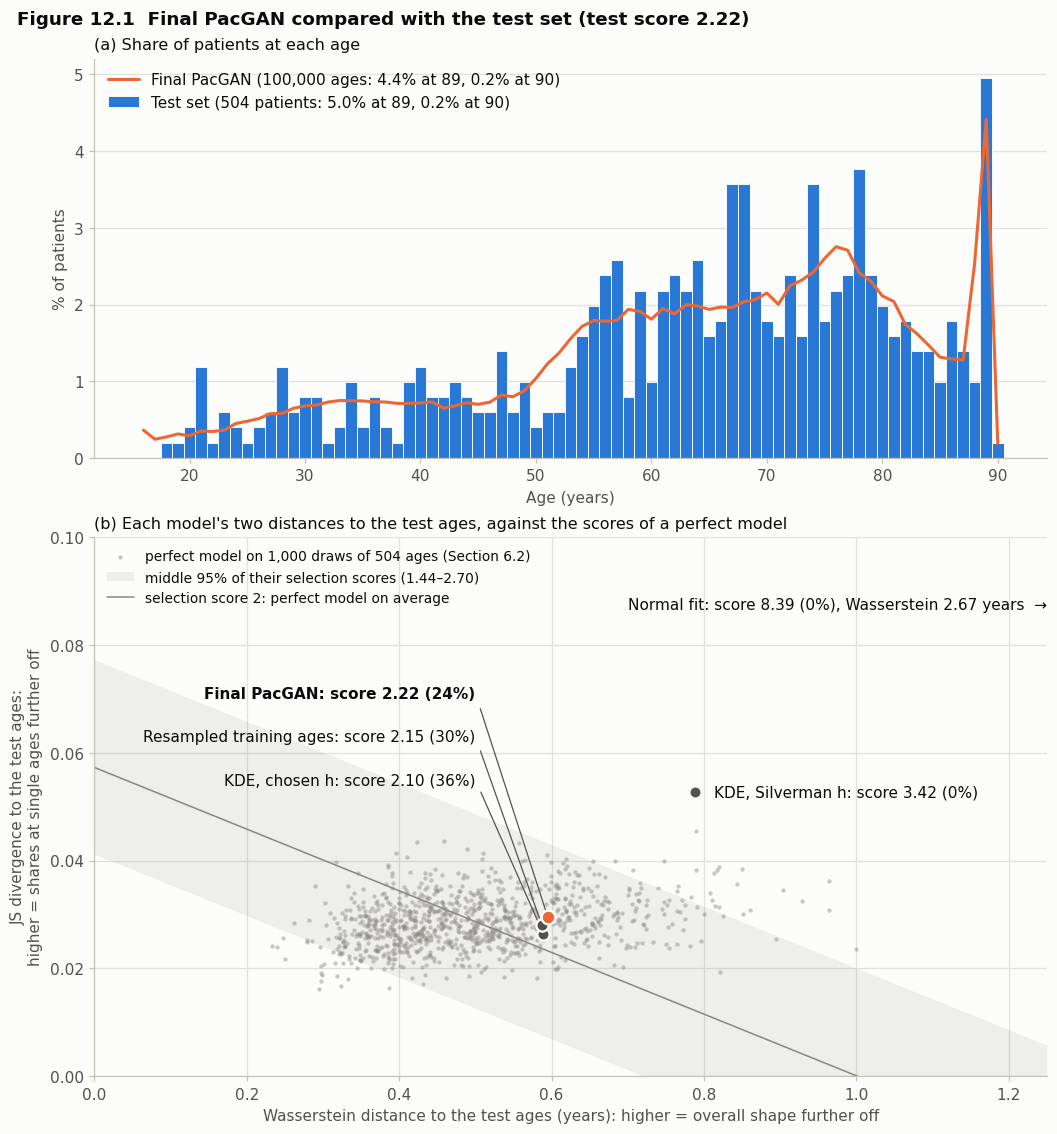

In [48]:
gan_hist, test_hist = model_hists[FINAL], hist_ages(age_test)
short = {FINAL: "Final PacGAN", **dict(zip(baselines, ["Normal fit", "KDE, chosen h", "KDE, Silverman h",
                                                        "Resampled training ages"]))}

fig, axes = plt.subplots(2, 1, figsize=(9.5, 10.2), layout="constrained", gridspec_kw={"height_ratios": [1, 1.35]})
r = test_results.loc[FINAL]
ax = axes[0]
ax.bar(AGES, 100 * test_hist, width=1.0, color=C["real"], edgecolor=C["surface"], linewidth=0.6,
       label=f"Test set ({n_test} patients: {100 * test_hist[I89]:.1f}% at 89, {100 * test_hist[-1]:.1f}% at 90)")
ax.plot(AGES, 100 * gan_hist, color=C["generated"],
        label=f"Final PacGAN ({N_GEN:,} ages: {r['% at 89']:.1f}% at 89, {r['% at 90']:.1f}% at 90)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("% of patients")
ax.legend(loc="upper left")
ax.set_title("(a) Share of patients at each age", fontsize=10.5, fontweight="normal")

# (b) Each model's two test distances against the scores a perfect model gets by chance, as in Figure 6.3. The
# perfect-model draws of Section 6.2 have 504 ages each, the size of the test set.
ax = axes[1]
ax.grid(True, axis="both")
fw, fj = floor["Wasserstein (years)"], floor["JS divergence"]
p_lo, p_hi = np.quantile(perfect_scores, [0.025, 0.975])
X_MAX, Y_MAX = 1.25, 0.10   # headroom at the top for the legend
w = np.array([0.0, X_MAX])
line = lambda s: fj * (s - w / fw)   # JS on the line of constant selection score s
band = ax.fill_between(w, line(p_lo), line(p_hi), color=to_rgba(C["ink2"], 0.08), linewidth=0)
mean_line, = ax.plot(w, line(2.0), color=C["muted"], linewidth=1)
dots = ax.scatter(floor_runs["Wasserstein (years)"], floor_runs["JS divergence"], s=8, color=C["muted"], alpha=0.45,
                  linewidth=0)

# The GAN and the two strong baselines almost coincide, so their labels are stacked in the empty space above the
# cloud (at these JS heights, ending at Wasserstein 0.5), highest point on top, each with a leader line to its point.
stacked = {"Final PacGAN": 0.071, "Resampled training ages": 0.063, "KDE, chosen h": 0.055}
for name in list(baselines) + [FINAL]:   # the GAN last, so it is drawn on top
    w1, js = test_results.loc[name, ["Wasserstein (years)", "JS divergence"]]
    label = (f"{short[name]}: score {test_results.loc[name, 'selection score']:.2f} "
             f"({t121.loc[name, 'perfect models as bad (%)']:.0f}%)")
    is_gan = name == FINAL
    if w1 <= X_MAX:
        ax.plot(w1, js, "o", markersize=9 if is_gan else 8, color=C["generated"] if is_gan else C["ink2"],
                markeredgecolor=C["surface"], markeredgewidth=1.5, zorder=4 if is_gan else 3)
        style = dict(va="center", color=C["ink"], fontweight="semibold" if is_gan else "normal")
        if short[name] in stacked:
            ax.annotate(label, (w1, js), xytext=(0.5, stacked[short[name]]), textcoords="data", ha="right",
                        arrowprops=dict(arrowstyle="-", color=C["ink2"], linewidth=0.8, shrinkA=4, shrinkB=5,
                                        relpos=(1, 0.5)),   # leader starts at the label's right end
                        **style)
        else:
            ax.annotate(label, (w1, js), xytext=(12, 0), textcoords="offset points", ha="left", **style)
    else:   # off the scale: label at the right edge, at its JS height
        ax.annotate(f"{label}, Wasserstein {w1:.2f} years  →", (1.0, js), xycoords=("axes fraction", "data"),
                    ha="right", va="center", color=C["ink"])
ax.set_xlim(0, X_MAX)
ax.set_ylim(0, Y_MAX)
ax.set_xlabel("Wasserstein distance to the test ages (years): higher = overall shape further off")
ax.set_ylabel("JS divergence to the test ages:\nhigher = shares at single ages further off")
ax.legend([dots, band, mean_line],
          [f"perfect model on {N_BOOT:,} draws of 504 ages (Section 6.2)",
           f"middle 95% of their selection scores ({p_lo:.2f}–{p_hi:.2f})",
           "selection score 2: perfect model on average"], loc="upper left", fontsize=9)
ax.set_title("(b) Each model's two distances to the test ages, against the scores of a perfect model",
             fontsize=10.5, fontweight="normal")
fig.suptitle(f"Figure 12.1  Final PacGAN compared with the test set (test score {r['selection score']:.2f})",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
fig.savefig(FIG_DIR / "fig12_1_final_model_vs_test.png")
plt.show()

**Figure 12.1.** The final PacGAN against the 504 test patients.
- *(a)* Share of test patients at each age (blue bars) and of 100,000 ages generated from fresh noise (orange
  line).
- *(b)* Each model's two distances to the test ages, laid out as in Figure 6.3.
  - *Axes:* Wasserstein distance (years) and JS divergence to the test set. Further right means the overall shape
    is further off; further up means the shares at single ages are further off, for example a smeared spike.
  - *Gray dots:* the 1,000 perfect-model draws from Section 6.2. Each has 504 ages, the size of the test set, so
    the cloud shows the scores a perfect model gets on the test set purely by chance.
  - *Diagonal lines:* constant selection score. The gray line is score 2, a perfect model on average; the shaded
    band holds the middle 95% of the perfect model's scores (1.44–2.70).
  - *Orange dot:* the final PacGAN; *dark dots:* the baselines. The percentage after each score is the share of
    perfect-model draws that score as badly or worse (Table 12.1). The normal fit is off the scale to the right
    (Wasserstein 2.67 years); its label sits at its JS divergence, 0.088.

How to read (b):
1. **The GAN and the two strong baselines sit inside the cloud, almost on top of each other** (Wasserstein 0.59
   years for all three; JS 0.026–0.030). On 504 test ages they cannot be told apart from each other or from a
   perfect model.
2. **The Silverman KDE is right on shape but wrong on the spike.** Its Wasserstein distance (0.79 years) is within
   the range of the gray dots, but its JS divergence (0.053) is above all of them, as on the validation set
   (Figure 6.3).

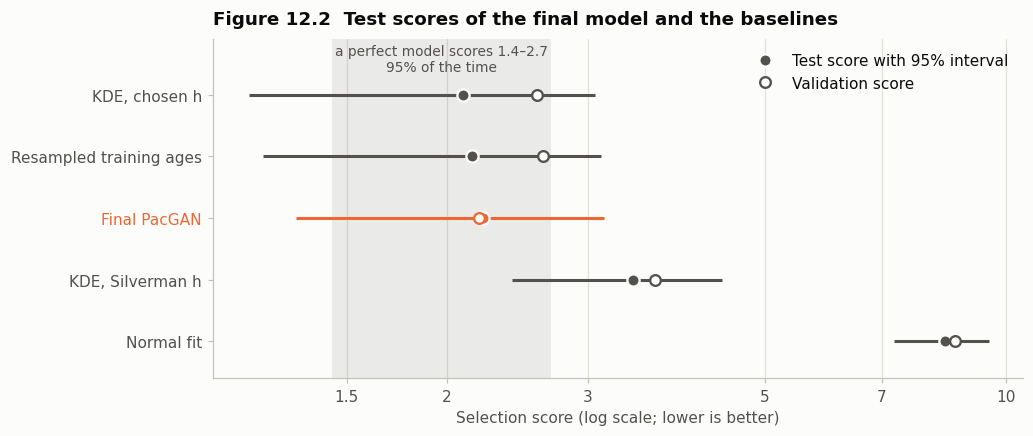

In [49]:
short = {FINAL: "Final PacGAN", **dict(zip(baselines, ["Normal fit", "KDE, chosen h", "KDE, Silverman h",
                                                        "Resampled training ages"]))}
order = models_by_test[::-1]   # best at the top
p_lo, p_hi = np.quantile(perfect_scores, [0.025, 0.975])

fig, ax = plt.subplots(figsize=(9.5, 4.0))
ax.axvspan(p_lo, p_hi, color=to_rgba(C["ink2"], 0.1), linewidth=0)
ax.annotate(f"a perfect model scores {p_lo:.1f}–{p_hi:.1f}\n95% of the time", ((p_lo * p_hi) ** 0.5, 1.0),
            xycoords=("data", "axes fraction"), xytext=(0, -3), textcoords="offset points", ha="center", va="top",
            color=C["ink2"], fontsize=9)
for y, name in enumerate(order):
    color = C["generated"] if name == FINAL else C["ink2"]
    s, half = t121.loc[name, "test score"], t121.loc[name, "± (95%)"]
    ax.plot([s - half, s + half], [y, y], color=color, linewidth=2, solid_capstyle="butt")
    ax.plot(s, y, "o", markersize=8, color=color, markeredgecolor=C["surface"], markeredgewidth=1.5,
            label="Test score with 95% interval" if y == 0 else None)
    ax.plot(t121.loc[name, "validation score"], y, "o", markersize=7, markerfacecolor=C["surface"],
            markeredgecolor=color, markeredgewidth=1.5, label="Validation score" if y == 0 else None)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([short[n] for n in order])
ax.get_yticklabels()[order.index(FINAL)].set_color(C["generated"])
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xscale("log")
xticks = [1, 1.5, 2, 3, 5, 7, 10, 15]
x_lo = min(1.5, min(t121.loc[order, "test score"] - t121.loc[order, "± (95%)"]) * 0.9)
x_hi = max(t121.loc[order, "test score"] + t121.loc[order, "± (95%)"]) * 1.1
ax.set_xticks([t for t in xticks if x_lo <= t <= x_hi])
ax.set_xticklabels([f"{t:g}" for t in xticks if x_lo <= t <= x_hi])
ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_xlim(x_lo, x_hi)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.set_xlabel("Selection score (log scale; lower is better)")
ax.legend(loc="upper right")
ax.set_title("Figure 12.2  Test scores of the final model and the baselines", pad=10)
fig.savefig(FIG_DIR / "fig12_2_test_scores.png")
plt.show()

**Figure 12.2.** The test selection score of each model (filled dots, with 95% intervals) next to its validation
score (open dots), best at the top. The final PacGAN is in orange; its two dots nearly coincide (2.20 and 2.22).
The gray band is the middle 95% of the scores a perfect model gets on a random set of 504 ages (Section 6.2): a
model inside the band is as close to the test ages as sampling noise allows. Log scale.

### 12.1 Findings

- **The final PacGAN is as close to the test ages as sampling noise allows (Table 12.1, Figure 12.1).**
  - Its test score is 2.22 ± 0.92. A perfect model scores 1.4–2.7 on 504 ages 95% of the time, and 24% of the
    perfect-model draws score 2.22 or worse.
  - In Figure 12.1 (b), it sits inside the cloud of perfect-model scores on both distances, almost on top of
    the two strong baselines.
- **Shape and spike.**
  - Wasserstein 0.59 years, KS 0.022 (the lowest of all models), JS 0.030.
  - 4.4% of generated ages are 89 (test 5.0%) and 0.2% are 90 (test 0.2%).
  - Mean 63.5 years (test 63.6), spread 18.0 (test 17.7), 5.8% under 30 (test 6.2%).
  - The generator is smooth where the test set is bumpy, for example at ages 67 and 68 (3.6% each in the test
    set; Figure 12.1 (a)).
- **Against the baselines (Table 12.2).**
  - The GAN clearly beats the normal fit (by 6.2) and the KDE with Silverman's bandwidth (by 1.2), which smears the
    spike into age 90.
  - It does not clearly beat the resampled training ages (difference +0.07, interval −0.49 to 0.63) or the KDE with
    its bandwidth chosen on validation (+0.12, interval −0.40 to 0.65).
  - By the paired rule (Table 12.2), these two count as ties.
  - By the perfect-model rule (Table 12.1), all three are indistinguishable from a perfect model on this test set:
    24% of perfect-model draws score as badly as the GAN or worse, 30% for the resampled training ages and 36%
    for the KDE.
- **Validation compared with test.**
  - The GAN scored 2.20 on validation and 2.22 on test.
  - The two strong baselines, whose validation scores involved no search, improved by about 0.5 (KDE 2.59 → 2.10;
    resampled training ages 2.64 → 2.15). So this test set happens to be closer to the training ages than the
    validation set was.
  - The GAN's validation score, in turn, was optimistic, because it is the best of many checkpoints and settings
    (Section 10.3). The two effects roughly cancel, and the GAN's validation lead over these baselines (about 0.4)
    does not hold on the test set.
- **What 504 test ages can resolve.** Each score is uncertain by about ±0.9. A difference between two good models is resolved only if it is larger than about ±0.55, the average half-width of the 95% intervals of the paired score differences (Table 12.2). Smaller differences cannot be told apart.

## 13. Conclusions and limitations

**What was built.** A PacGAN in TensorFlow.
- The generator and the discriminator are small fully connected networks, trained on the 1,512 training ages with
  the standard GAN loss.
- The discriminator judges packs of 4 ages, which makes a generator with too little variety easy to catch.

**How the two networks coordinate.**
- Both losses settle at their balance values within about 100 steps, so the losses say little about quality
  (Figures 9.1 and 11.1).
- The discriminator's response to each age shows the exchange. It flags ages the generator makes too few or too
  many of, most clearly the spike at 89, and the generator follows (Figures 11.2 and 11.3).
- At the best checkpoint the response is almost flat: the equilibrium a GAN aims for.

**How good the generated ages are (test set, opened once).**
- Score 2.22, where a perfect model scores about 2 (95% range 1.4–2.7). The test set cannot tell the GAN from a
  perfect model.
- Wasserstein 0.59 years and KS 0.022 (the lowest of all models). 4.4% of ages at 89 (test 5.0%) and 0.2% at 90
  (test 0.2%). Mean 63.5 (test 63.6) and spread 18.0 (test 17.7).
- The GAN clearly beats a normal fit and a KDE with the textbook bandwidth. It ties with simply resampling the
  training ages and with a KDE whose bandwidth was tuned on validation.

**What made it work.**
1. A protocol that prevents data leakage: split first; train to fit, validation to choose, test once.
2. A selection score chosen by simulation (Section 7): Wasserstein distance for the overall shape plus JS
   divergence for single ages such as the spike, each divided by its noise floor.
3. Keeping the best checkpoint, because the GAN's quality swings from one check to the next.
4. Judging settings by the median of 3 seeds, because one run's score is partly luck.

**Limitations.**
- **One variable, 2,520 patients.** For a single variable, resampling or a KDE does as well as the GAN. A GAN earns
  its place with several variables, where those simple methods break down. Here it demonstrates the method.
- **Data kept as stored.** The spike at 89 is the eICU "> 89" cap, not a real age. The model reproduces the coding,
  not the true ages of the oldest patients.
- **Small evaluation sets.** With 504 ages, score differences under about 0.5 cannot be resolved, and the
  validation score of a chosen model is optimistic.
- **Unsteady training.** Quality swings between checks (scores from about 2.2 to 3.5 late in training), so the
  result depends on choosing a checkpoint with the validation set.
- **Exact reproducibility.** Runs repeat exactly on this machine and TensorFlow version (CPU, deterministic
  operations), but not necessarily on other hardware.

**Next steps.**
- Add more variables, for example sex or admission type, and generate them together with age (a conditional GAN).
- Model the "> 89" category explicitly instead of as an age.
- Average the generator's weights over recent steps, to reduce the swings between checks and the dependence on
  checkpoint choice.
- Use cross-validation for the choices, to make better use of a small dataset.